# Практичне завдання 2: багатокласова логістична регресія на NumPy та федеративне навчання (FedAvg)

**Датасет:** Dry Bean Dataset (Koklu & Ozkan, 2020) — 13 611 зерен, 7 сортів квасолі, 16 числових ознак.

**Що реалізовано (усе «з нуля» на NumPy):**

| Етап | Зміст |
|---|---|
| 1 | EDA, стратифікований поділ Global Test / Global Validation / FL Train Pool, one-hot, StandardScaler без Data Leakage |
| 2 | Клас `MulticlassLogisticRegression`: softmax, cross-entropy + Ridge, градієнти, міні-батчевий GD (повністю векторизовано) |
| 3 | Централізована базова модель: підбір learning rate, batch size, λ на Global Validation; оцінка на Global Test |
| 4 | Розподіл FL Train Pool між K=5 клієнтами: IID та Non-IID (Діріхле, параметр α), візуалізація |
| 5 | Симуляція FedAvg (зважена агрегація за $n_k$) |
| 6 | Експеримент 1 (вплив α), Експеримент 2 (вплив числа локальних епох E), порівняльна таблиця Local / Global / Centralized |
| 7 | Додатковий експеримент Б: персоналізація |
| — | Відповіді на теоретичні питання та загальний висновок |

**Обмеження, яких дотримано:**
* модель, функція втрат, градієнти та агрегація ваг — лише `numpy`, без циклів по прикладах (цикли є тільки по епохах, батчах, клієнтах, раундах);
* `sklearn` використано **лише** для `train_test_split`, `StandardScaler` та метрик (`accuracy`, `macro-F1`, `balanced accuracy`, `log-loss`, `confusion_matrix`); `LogisticRegression`/`SGDClassifier` не використовуються взагалі;
* усі випадкові процеси мають фіксований seed → результати відтворювані;
* усі графіки відображаються безпосередньо в ноутбуці.

> **Файл з даними.** Ноутбук шукає `Dry_Bean_Dataset.xlsx` (або `.csv` / `.arff`) у поточній папці; якщо файлу немає — завантажує датасет з UCI через `ucimlrepo` (`pip install ucimlrepo`).

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn — ТІЛЬКИ для розбиття, масштабування та метрик
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             log_loss, confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                      # seed для розбиття даних та базових експериментів
SEEDS = [0, 1, 2, 3, 4]        # набір seed-ів для повторів FL-експериментів (усереднення)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


---
# Етап 1. Підготовка даних

## 1.1 Вибір датасету та його придатність для федеративного навчання

Використовується **Dry Bean Dataset**: 13 611 зерен 7 сортів (*Seker, Barbunya, Bombay, Cali, Dermason, Horoz, Sira*), для кожного зерна комп'ютерний зір видобув 16 числових ознак (12 геометричних розмірів і 4 коефіцієнти форми).

Чому він добре підходить для FL:

1. **Багатокласова задача** (7 класів ≥ 3) — виконано вимогу завдання.
2. **Достатньо прикладів** для розподілу між кількома клієнтами: після відокремлення тесту й валідації в FL Train Pool залишається ≈10 200 прикладів, тобто ≈2 000 на клієнта при K=5 (а при K=10 — ≈1 000).
3. **Чисті табличні числові ознаки, без пропусків** → можна зосередитися на самому FL, а не на очищенні даних; лінійна softmax-модель має малу кількість параметрів ($16\cdot 7 + 7 = 119$), тому швидко навчається й агрегується.
4. **Природний сценарій Non-IID:** різні господарства, склади чи сортувальні лінії бачать різний набір сортів. Клас-дисбаланс датасету (Dermason ≈ 26 %, Bombay ≈ 4 %) робить поведінку FedAvg при неоднорідних даних наочною.
5. **Приватність мотивована реально:** дані з сортувальних ліній різних виробників — комерційно чутливі, тож не передавати сирі вимірювання на сервер має сенс.

*Джерело:* KOKLU, M., OZKAN, I.A. (2020). *Multiclass classification of dry beans using computer vision and machine learning techniques.* Computers and Electronics in Agriculture, 174, 105507. https://doi.org/10.1016/j.compag.2020.105507

In [2]:
def load_dry_bean():
    """Завантажує датасет: локальний файл (xlsx/csv/arff) або UCI (fetch_ucirepo, id=602)."""
    for name in ["Dry_Bean_Dataset.xlsx", "Dry_Bean_Dataset.csv", "Dry_Bean_Dataset.arff"]:
        p = Path(name)
        if not p.exists():
            continue
        if p.suffix == ".xlsx":
            return pd.read_excel(p), f"локальний файл {name}"
        if p.suffix == ".csv":
            return pd.read_csv(p), f"локальний файл {name}"
        from scipy.io import arff
        data, _ = arff.loadarff(p)
        d = pd.DataFrame(data)
        d["Class"] = d["Class"].apply(lambda s: s.decode() if isinstance(s, bytes) else s)
        return d, f"локальний файл {name}"
    from ucimlrepo import fetch_ucirepo                      # запасний варіант
    ds = fetch_ucirepo(id=602)
    d = ds.data.features.copy()
    d["Class"] = ds.data.targets["Class"].values
    return d, "UCI repository (fetch_ucirepo)"


df, source = load_dry_bean()
print(f"Джерело даних: {source}")
print(f"Розмір таблиці: {df.shape[0]} рядків × {df.shape[1]} стовпців")
df.head()

Джерело даних: локальний файл Dry_Bean_Dataset.xlsx
Розмір таблиці: 13611 рядків × 17 стовпців


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.018,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.110,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.884,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.134,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


## 1.2 Базовий EDA

EDA на цьому етапі **описовий** (структура, пропуски, баланс класів, шкали ознак) і не використовується для жодних рішень щодо моделі — усі рішення про ознаки приймаються нижче лише за даними FL Train Pool.

In [3]:
# --- структура, типи, пропуски, дублікати ---
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "пропуски": df.isna().sum(),
                     "унікальних": df.nunique()})
display(info)
print(f"Усього пропусків: {int(df.isna().sum().sum())}")
print(f"Повних дублікатів рядків: {int(df.duplicated().sum())} ({df.duplicated().mean():.2%})")

,dtype,пропуски,унікальних
Area,int64,0,12011
Perimeter,float64,0,13416
MajorAxisLength,float64,0,13543
MinorAxisLength,float64,0,13543
AspectRation,float64,0,13543
Eccentricity,float64,0,13543
ConvexArea,int64,0,12066
EquivDiameter,float64,0,12011
Extent,float64,0,13535
Solidity,float64,0,13526


Усього пропусків: 0
Повних дублікатів рядків: 68 (0.50%)


,кількість,частка
Class,,
DERMASON,3546,0.2605
SIRA,2636,0.1937
SEKER,2027,0.1489
HOROZ,1928,0.1417
CALI,1630,0.1198
BARBUNYA,1322,0.0971
BOMBAY,522,0.0384


Дисбаланс (найбільший/найменший клас): 6.8×


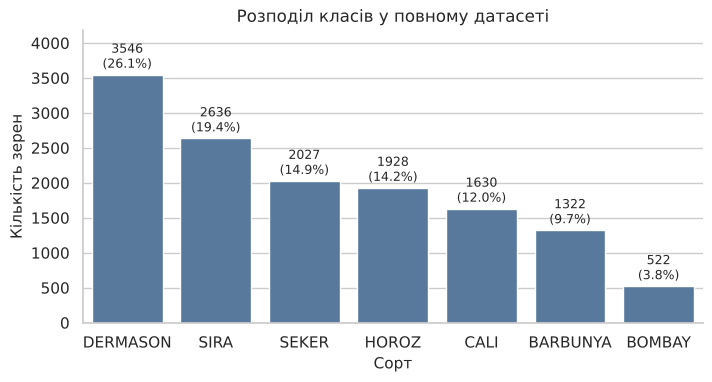

In [4]:
# --- розподіл цільової змінної ---
class_counts = df["Class"].value_counts()
class_share = (class_counts / len(df)).rename("частка")
display(pd.concat([class_counts.rename("кількість"), class_share], axis=1))
print(f"Дисбаланс (найбільший/найменший клас): {class_counts.max() / class_counts.min():.1f}×")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#4C78A8", ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 40, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, class_counts.max() * 1.18)
ax.set_title("Розподіл класів у повному датасеті"); ax.set_xlabel("Сорт"); ax.set_ylabel("Кількість зерен")
plt.show()

,count,mean,std,min,25%,50%,75%,max,skew
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000,2.9529
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700,1.6261
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602,1.3578
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985,2.2382
AspectRation,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303,0.5826
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114,-1.0628
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000,2.9418
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744,1.9490
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662,-0.8953
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,-2.5501


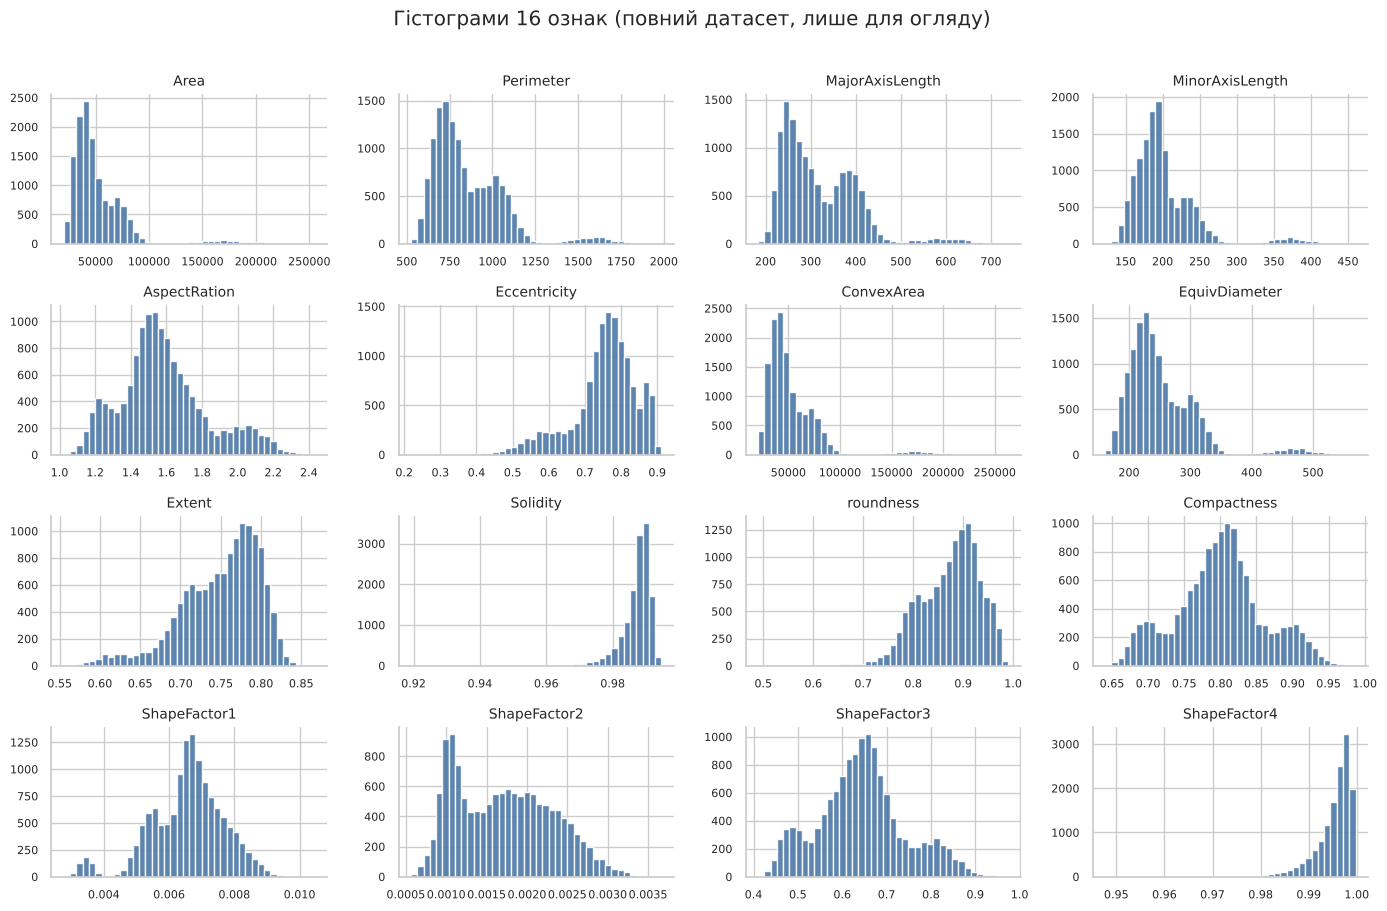

In [5]:
# --- основні статистики числових ознак ---
FEATURES = [c for c in df.columns if c != "Class"]
stats = df[FEATURES].describe().T
stats["skew"] = df[FEATURES].skew()
display(stats)

fig, axes = plt.subplots(4, 4, figsize=(14, 9))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.hist(df[f], bins=40, color="#4C78A8", alpha=0.9)
    ax.set_title(f, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle("Гістограми 16 ознак (повний датасет, лише для огляду)", y=1.01)
plt.tight_layout(); plt.show()

### Висновки EDA

* **Структура.** 13 611 рядків × 16 числових ознак (`int64`/`float64`) + цільова змінна `Class` (7 сортів). **Пропусків немає** (0), тому імпутація не потрібна. Є 68 повних дублікатів (0.5 %) — вони залишені без змін, щоб не модифікувати вихідний датасет; в крайньому випадку такий рядок може потрапити і в train, і в test, що дає ледь помітне (< 0.5 %) оптимістичне зміщення метрик.
* **Баланс класів.** Клас помірно незбалансований: Dermason — 26.1 %, Bombay — лише 3.8 % (відношення 6.8×). Наслідки: (1) поділ має бути **стратифікованим**, інакше рідкісний клас (Bombay, ≈520 зерен) може непропорційно потрапити в одну з вибірок; (2) крім accuracy потрібні **macro-F1 і balanced accuracy**; (3) при Non-IID-розподілі цей клас легко «зникає» у більшості клієнтів.
* **Шкали ознак.** Ознаки живуть у різних масштабах: `Area` ≈ 2·10⁴–2.5·10⁵, `ConvexArea` — того ж порядку, а `Solidity`, `ShapeFactor4` ≈ 0.99, `ShapeFactor1` ≈ 0.007. Ознаки площі/периметра мають сильний правий хвіст (skew ≈ 1.4–3.0), `Solidity` і `ShapeFactor4` — лівий (skew ≈ −2.6). Для градієнтного спуску це означає погано зумовлену задачу й нестабільний вибір learning rate → **стандартизація обов'язкова**.
* **Категоріальні ознаки.** Усі ознаки числові, тому кодування потрібне лише для цілі. Обрано **One-Hot**: класи номінальні (порядку між сортами немає), тому Ordinal Encoding вніс би хибний порядок; Target Encoding до самої цільової змінної не застосовний (і створює leakage).

## 1.3 Стратифікований поділ: Global Test / Global Validation / FL Train Pool

**Схема поділу (виконується ПЕРШИМ кроком — до кодування, масштабування чи відбору ознак):**

```
                    Повний датасет (13 611)
                              │
          stratified split (за класом, random_state=SEED)
        ┌─────────────────────┼──────────────────────────┐
        ▼                     ▼                          ▼
  Global Test (15 %)   Global Validation (10 %)   FL Train Pool (75 %)
  лише на сервері;     лише на сервері;           ┌── розподіляється між K клієнтами
  фінальна оцінка      підбір гіперпараметрів,    │   (IID / Non-IID Діріхле) — Етап 4
                       моніторинг раундів         └── сервер НЕ бачить цих сирих даних
```

Спочатку відокремлюємо 15 % на тест, потім із решти 85 % беремо `0.10 / 0.85 ≈ 11.76 %`, що дає рівно 10 % від усього датасету.

### Чому поділ ПЕРЕД масштабуванням, кодуванням чи відбором ознак? Що таке Data Leakage

**Data Leakage (витік даних)** — ситуація, коли під час навчання (або підготовки до нього) модель прямо чи опосередковано отримує інформацію з даних, яких вона не мала б бачити в реальності (валідація/тест/майбутнє). Метрики стають **завищеними й неправдивими**: модель «знає відповіді» і гірше працює на справді нових даних.

Приклад саме тут: якщо обчислити середнє та стандартне відхилення за **всім** датасетом і лише потім ділити, то параметри масштабування вже містять інформацію про тестові приклади. Те саме стосується відбору ознак за кореляціями з ціллю, підбору гіперпараметрів за тестом, target encoding тощо. У федеративному сценарії це ще й порушує сам сенс системи: клієнти не мають бачити Global Test / Global Validation, а сервер — сирі дані клієнтів.

**Правило:** будь-яка операція, що «навчається» на даних (`fit` скалера, вибір ознак, пошук гіперпараметрів), виконується **тільки на тренувальній частині** (тут — FL Train Pool); до валідації й тесту застосовується лише `transform` з уже навченими параметрами.

In [6]:
# --- кодування міток (без sklearn: np.unique) ---
classes, y_all = np.unique(df["Class"].to_numpy(), return_inverse=True)   # classes — відсортовані назви
C = len(classes)                                                          # кількість класів
X_all = df[FEATURES].to_numpy(dtype=np.float64)

TEST_SIZE, VAL_SIZE = 0.15, 0.10

# 1) Global Test (15 %)
X_rest, X_test_raw, y_rest, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
# 2) Global Validation (10 % від усього) з решти 85 %; те, що лишилось, — FL Train Pool (75 %)
X_pool_raw, X_val_raw, y_pool, y_val = train_test_split(
    X_rest, y_rest, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y_rest, random_state=SEED)

split_df = pd.DataFrame({
    "Global Test": np.bincount(y_test, minlength=C),
    "Global Validation": np.bincount(y_val, minlength=C),
    "FL Train Pool": np.bincount(y_pool, minlength=C)}, index=classes)
split_df.loc["УСЬОГО"] = split_df.sum()
display(split_df)
print("Частка кожної вибірки від усього датасету:",
      {k: f"{v / len(df):.1%}" for k, v in split_df.loc["УСЬОГО"].items()})
cnt_only = split_df.drop(index="УСЬОГО")
display((cnt_only / cnt_only.sum(axis=0) * 100).round(2).rename(columns=lambda c: c + ", % від вибірки"))   # частка класу всередині кожної вибірки

,Global Test,Global Validation,FL Train Pool
BARBUNYA,198,132,992
BOMBAY,78,52,392
CALI,245,163,1222
DERMASON,532,355,2659
HOROZ,289,193,1446
SEKER,304,203,1520
SIRA,396,264,1976
УСЬОГО,2042,1362,10207


Частка кожної вибірки від усього датасету: {'Global Test': '15.0%', 'Global Validation': '10.0%', 'FL Train Pool': '75.0%'}


,"Global Test, % від вибірки","Global Validation, % від вибірки","FL Train Pool, % від вибірки"
BARBUNYA,9.70,9.69,9.72
BOMBAY,3.82,3.82,3.84
CALI,12.00,11.97,11.97
DERMASON,26.05,26.06,26.05
HOROZ,14.15,14.17,14.17
SEKER,14.89,14.90,14.89
SIRA,19.39,19.38,19.36


### Висновок щодо поділу

Отримано **Global Test = 2 042 (15.0 %)**, **Global Validation = 1 362 (10.0 %)**, **FL Train Pool = 10 207 (75.0 %)**. Частки кожного класу в трьох вибірках збігаються з точністю ≈ 0.05 процентного пункту (наприклад, Bombay: 3.82 % / 3.82 % / 3.84 %), тобто стратифікація спрацювала, і метрики на валідації та тесті порівнювані між собою. Дивлячись на розмір пулу, ≈ 2 000 прикладів на клієнта (K=5) для 119-параметричної лінійної моделі — достатньо для локального навчання, що зробить порівняння «локальна vs глобальна» нетривіальним лише за рахунок неоднорідності, а не нестачі даних.

In [7]:
# --- One-Hot кодування цільової змінної: Y ∈ {0,1}^{m×C} ---
def one_hot(y, n_classes):
    return np.eye(n_classes)[y]

Y_pool, Y_val, Y_test = one_hot(y_pool, C), one_hot(y_val, C), one_hot(y_test, C)
print("Класи:", dict(enumerate(classes)))
print("Y_pool:", Y_pool.shape, "| приклад мітки:", y_pool[0], "→", Y_pool[0])

# --- StandardScaler: fit ТІЛЬКИ на FL Train Pool, потім transform до val та test ---
scaler = StandardScaler().fit(X_pool_raw)
X_pool_all = scaler.transform(X_pool_raw)
X_val_all = scaler.transform(X_val_raw)
X_test_all = scaler.transform(X_test_raw)

chk = pd.DataFrame({
    "mean (pool)": X_pool_all.mean(0), "std (pool)": X_pool_all.std(0),
    "mean (val)": X_val_all.mean(0), "std (val)": X_val_all.std(0),
    "mean (test)": X_test_all.mean(0), "std (test)": X_test_all.std(0)}, index=FEATURES)
assert np.allclose(chk["mean (pool)"], 0, atol=1e-9) and np.allclose(chk["std (pool)"], 1)
display(chk.round(3))

Класи: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Y_pool: (10207, 7) | приклад мітки: 6 → [0. 0. 0. 0. 0. 0. 1.]


,mean (pool),std (pool),mean (val),std (val),mean (test),std (test)
Area,0.0,1.0,-0.005,0.989,0.002,0.983
Perimeter,0.0,1.0,-0.006,0.990,0.006,0.990
MajorAxisLength,0.0,1.0,-0.002,0.996,0.004,0.993
MinorAxisLength,-0.0,1.0,-0.010,0.996,0.007,0.982
AspectRation,-0.0,1.0,0.012,0.999,-0.004,0.996
Eccentricity,0.0,1.0,0.013,0.991,-0.002,0.999
ConvexArea,0.0,1.0,-0.006,0.987,0.002,0.983
EquivDiameter,-0.0,1.0,-0.006,0.997,0.006,0.988
Extent,0.0,1.0,-0.049,1.020,0.028,0.996
Solidity,0.0,1.0,-0.000,1.046,0.011,0.959


### Висновок щодо кодування та масштабування

* One-hot матриця `Y` має форму `(m, 7)`, кожен рядок містить рівно одну одиницю.
* Скалер **навчений лише на FL Train Pool**: у пулі середнє = 0 і std = 1 *за побудовою*, тоді як у валідації та тесті вони **відрізняються** (наприклад, середнє `Extent` у валідації −0.049, std `Solidity` — 1.046). Саме так і має бути: це свідчить, що параметри валідації/тесту у скалер не потрапили (інакше всюди було б рівно 0 і 1).
* **Який варіант федеративного масштабування використано.** Згідно з вимогами завдання, це *спрощений* підхід (а): скалер навчається на всьому FL Train Pool **до** розподілу даних між клієнтами, і це явно є **частиною симуляції** (у реальній системі сервер не мав би доступу до всього пулу). Повністю федеративний варіант (б) дав би *математично той самий результат*: кожен клієнт надсилає $(n_k,\mu_k,\sigma_k^2)$, сервер обчислює $\mu=\sum_k \tfrac{n_k}{n}\mu_k$ та $\sigma^2=\sum_k\tfrac{n_k}{n}(\sigma_k^2+\mu_k^2)-\mu^2$ — це рівно ті самі глобальні статистики, що дає `StandardScaler` на об'єднаному пулі; відмінність лише в тому, що сирі дані не залишають клієнтів.

## 1.4 Аналіз та відбір ознак (виключно на FL Train Pool)

Аналіз для відбору ознак виконується **тільки на FL Train Pool** (тестова й валідаційна вибірки не використовуються):

* **зв'язок ознака ↔ клас.** Оскільки ціль категоріальна, замість коефіцієнта Пірсона використовуємо *кореляційне відношення* $\eta^2\in[0,1]$ — частку дисперсії ознаки, що пояснюється приналежністю до класу: $\eta^2=\dfrac{\sum_c n_c(\bar x_c-\bar x)^2}{\sum_i (x_i-\bar x)^2}$ (векторизовано через one-hot матрицю);
* **зв'язок ознака ↔ ознака.** Матриця кореляцій Пірсона для виявлення **мультиколінеарності** (багато ознак — це різні функції від тих самих площі/периметра/осей);
* **жадібний відбір:** ознаки перебираються за спаданням $\eta^2$, ознака залишається, якщо $|r|<0.95$ з усіма вже відібраними.

Мультиколінеарність не ламає передбачення, але робить коефіцієнти нестабільними, а оптимізацію — погано обумовленою (повільна збіжність GD). Ridge-регуляризація частково це лікує. Остаточне рішення «усі 16 ознак чи скорочений набір» ми приймаємо **емпірично на Global Validation** на Етапі 3.

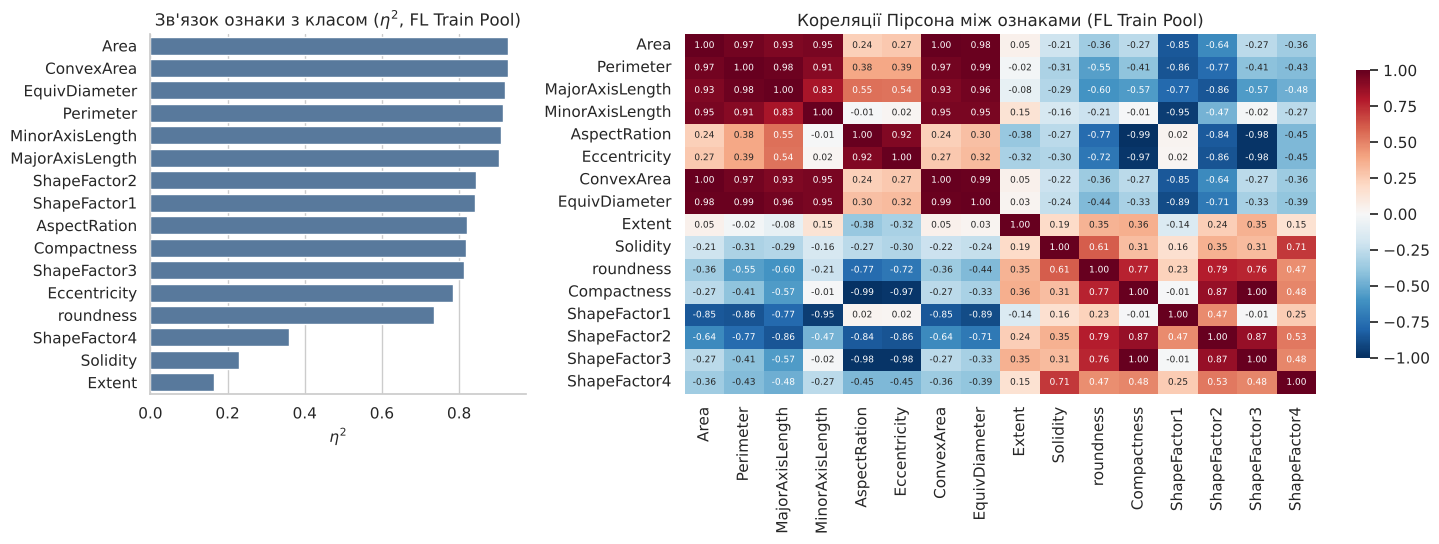

Пар ознак з |r| > 0.95: 15


,ознака 1,ознака 2,r
0,Area,ConvexArea,0.9999
1,Compactness,ShapeFactor3,0.9987
2,Perimeter,EquivDiameter,0.9914
3,AspectRation,Compactness,-0.9876
4,ConvexArea,EquivDiameter,0.9851
5,Area,EquivDiameter,0.9849
6,Eccentricity,ShapeFactor3,-0.9807
7,AspectRation,ShapeFactor3,-0.9785
8,Perimeter,MajorAxisLength,0.9774
9,Eccentricity,Compactness,-0.9698



Скорочений набір (10 ознак): ['Area', 'MajorAxisLength', 'ShapeFactor2', 'ShapeFactor1', 'AspectRation', 'Eccentricity', 'roundness', 'ShapeFactor4', 'Solidity', 'Extent']
Відкинуті як надлишкові (6): ['Perimeter', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter', 'Compactness', 'ShapeFactor3']


In [8]:
def correlation_ratio(X, y, n_classes):
    """η² для кожної ознаки (векторизовано): частка дисперсії, пояснена класом."""
    Y1 = np.eye(n_classes)[y]
    counts = Y1.sum(axis=0)
    class_means = (Y1.T @ X) / counts[:, None]
    grand = X.mean(axis=0)
    ss_between = (counts[:, None] * (class_means - grand) ** 2).sum(axis=0)
    ss_total = ((X - grand) ** 2).sum(axis=0)
    return ss_between / ss_total


eta2 = pd.Series(correlation_ratio(X_pool_all, y_pool, C), index=FEATURES).sort_values(ascending=False)
corr = pd.DataFrame(X_pool_all, columns=FEATURES).corr()          # кореляції лише на FL Train Pool

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 2.1]})
sns.barplot(x=eta2.values, y=eta2.index, color="#4C78A8", ax=axes[0])
axes[0].set_title(r"Зв'язок ознаки з класом ($\eta^2$, FL Train Pool)"); axes[0].set_xlabel(r"$\eta^2$"); axes[0].set_ylabel("")
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title("Кореляції Пірсона між ознаками (FL Train Pool)")
plt.tight_layout(); plt.show()

# пари з |r| > 0.95
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "ознака 1", "level_1": "ознака 2"}))
strong = pairs[pairs["r"].abs() > 0.95].sort_values("r", key=np.abs, ascending=False)
print(f"Пар ознак з |r| > 0.95: {len(strong)}")
display(strong.reset_index(drop=True))

# --- жадібний відбір неколінеарних ознак ---
def select_uncorrelated(corr_matrix, order, thr=0.95):
    kept = []
    for f in order:                                   # цикл по ОЗНАКАХ (їх 16) — не по прикладах
        if all(abs(corr_matrix.loc[f, k]) < thr for k in kept):
            kept.append(f)
    return kept

REDUCED = select_uncorrelated(corr, list(eta2.index), thr=0.95)
dropped = [f for f in FEATURES if f not in REDUCED]
print(f"\nСкорочений набір ({len(REDUCED)} ознак): {REDUCED}")
print(f"Відкинуті як надлишкові ({len(dropped)}): {dropped}")

### Висновки щодо ознак

* **Зв'язок з класом ($\eta^2$).** Найінформативніші — ознаки розміру: `Area`, `ConvexArea`, `EquivDiameter`, `Perimeter`, `MinorAxisLength`, `MajorAxisLength` ($\eta^2\approx0.90$–0.93; сорт значною мірою визначає розмір зерна — Bombay найбільший), далі `ShapeFactor1/2`, `AspectRation`, `Compactness` ($\approx0.8$). Найслабші: `Extent` (0.16), `Solidity` (0.23), `ShapeFactor4` (0.36).
* **Мультиколінеарність дуже сильна.** 15 пар ознак мають $|r|>0.95$: `Area`–`ConvexArea` (0.9999), `Compactness`–`ShapeFactor3` (0.9987), `Perimeter`–`EquivDiameter` (0.991), `AspectRation`–`Compactness` (−0.988) тощо. Причина — ознаки є функціями від тих самих величин (площі, периметра, осей еліпса). Для лінійної моделі це означає майже виродженну матрицю $X^\top X$: коефіцієнти нестабільні та погано інтерпретовані, збіжність GD — повільна; передбачення при цьому лишаються коректними.
* **Кандидат на відбір:** жадібна процедура залишила **10 ознак** і відкинула `Perimeter`, `MinorAxisLength`, `ConvexArea`, `EquivDiameter`, `Compactness`, `ShapeFactor3`. Слабкі за $\eta^2$ ознаки (`Extent`, `Solidity`, `ShapeFactor4`) **не відкидалися**: низька одновимірна залежність від цілі не означає марності в комбінації з іншими, а критерієм відбору була лише надлишковість.
* Усе це — лише гіпотеза; **остаточно набір обирається на Global Validation** (Етап 3.0). Тестова вибірка в аналізі не використовувалась.

---
# Етап 2. Реалізація багатокласової логістичної регресії на NumPy

## 2.1 Теоретична основа

Нехай $X\in\mathbb R^{m\times d}$, $Y\in\{0,1\}^{m\times C}$ (one-hot), параметри $W\in\mathbb R^{d\times C}$, $b\in\mathbb R^{1\times C}$.

$$Z = XW + b,\qquad P=\mathrm{softmax}(Z),\quad P_{ic}=\frac{e^{Z_{ic}}}{\sum_{j}e^{Z_{ij}}}$$

$$J(W,b) = -\frac1m\sum_{i=1}^m\sum_{c=1}^C Y_{ic}\log P_{ic}\;+\;\frac{\lambda}{2}\lVert W\rVert_F^2$$

$$\frac{\partial J}{\partial W}=\frac1m X^\top (P-Y)+\lambda W,\qquad \frac{\partial J}{\partial b}=\frac1m \mathbf 1_m^\top (P-Y)$$

**Виведення.** Для одного прикладу $\ell=-\sum_c y_c\log p_c$, $p=\mathrm{softmax}(z)$. Оскільки $\partial p_c/\partial z_k=p_c(\delta_{ck}-p_k)$ і $\sum_c y_c=1$, отримуємо $\partial \ell/\partial z_k = p_k-y_k$. Усереднення за $m$ прикладами та $Z=XW+b$ дають формули вище; Ridge додає $\lambda W$ (похідна від $\frac\lambda2\lVert W\rVert^2$).

**Чисельна стабільність.** $\mathrm{softmax}(Z)=\mathrm{softmax}(Z-\max_j Z_{ij})$ — віднімання максимуму рядка не змінює результат, але запобігає переповненню `exp` (без цього $e^{1000}=\infty$). Для самої втрати використовуємо ще й log-softmax $\log P_{ic}=Z_{ic}-\log\sum_j e^{Z_{ij}}$, щоб не брати `log(0)`.

## 2.2 Теоретичні пояснення щодо вибору функцій

* **Чому softmax?** Для $C>2$ потрібен вихід, який є розподілом ймовірностей: невід'ємні числа, що сумуються до 1. Softmax — це узагальнення сигмоїди на $C$ класів, він диференційовний, зберігає порядок логітів (argmax не змінюється) і є канонічною функцією зв'язку для категоріального розподілу.
* **Чому крос-ентропія?** Мінімізація крос-ентропії ≡ **максимізація правдоподібності** (MLE) категоріальної моделі: $-\log\prod_i P_{i,y_i}$. Разом із softmax вона дає дуже простий градієнт $P-Y$ та **опуклу** задачу (мінімум єдиний, GD не застрягає в локальних мінімумах). З MSE градієнт «гасився» б насиченням softmax.
* **Ridge (L2) проти Lasso (L1).** Ridge штрафує $\lVert W\rVert_2^2$: стискає ваги до нуля плавно, не обнуляє їх, добре працює при мультиколінеарності, диференційовний скрізь (градієнт $\lambda W$). Lasso штрафує $\lVert W\rVert_1$: дає розріджені розв'язки (вбудований відбір ознак), але не диференційовний у нулі й нестабільний для сильно корельованих ознак.
* **Чому $b$ не регуляризують?** Зсув лише переносить поріг рішення й не контролює складність (чутливість) моделі; штраф на $b$ змушував би передбачення тяжіти до рівноймовірних класів, навіть якщо реальні частоти класів відрізняються, і робив би модель залежною від зсуву цілі/ознак.
* **Відбір ознак і Data Leakage.** Відбір ознак — це теж «навчання на даних». Якщо відбирати ознаки за кореляціями з ціллю на всьому датасеті (включно з тестом), рішення стають залежними від тесту (leakage), а тестові метрики — оптимістичними. Тому тут відбір робиться лише за FL Train Pool, а вибір між наборами ознак — за Global Validation.

In [9]:
class MulticlassLogisticRegression:
    """Багатокласова логістична регресія (softmax) з Ridge-регуляризацією — чистий NumPy.

    Параметри: W (d×C), b (1×C). Ridge-штраф  (λ/2)·‖W‖²_F  діє ЛИШЕ на W (b не регуляризується).
    Усі обчислення втрат і градієнтів векторизовані: жодних циклів по прикладах.
    Цикли є тільки в `fit` (по епохах і міні-батчах).
    """

    def __init__(self, n_features, n_classes, lam=0.0):
        self.d, self.C, self.lam = n_features, n_classes, lam
        self.W = np.zeros((n_features, n_classes))      # w⁰ = 0: детермінована, однакова для всіх клієнтів ініціалізація
        self.b = np.zeros((1, n_classes))

    # ---------- параметри (потрібні для FL: сервер ↔ клієнт) ----------
    def get_params(self):
        return self.W.copy(), self.b.copy()

    def set_params(self, W, b):
        self.W, self.b = W.copy(), b.copy()

    # ---------- прямий прохід ----------
    @staticmethod
    def softmax(Z):
        """Стабільний softmax по рядках: віднімаємо максимум рядка перед exp."""
        Z_shift = Z - Z.max(axis=1, keepdims=True)
        expZ = np.exp(Z_shift)
        return expZ / expZ.sum(axis=1, keepdims=True)

    def predict_proba(self, X):
        return self.softmax(X @ self.W + self.b)

    def predict(self, X):
        return np.argmax(X @ self.W + self.b, axis=1)    # argmax логітів = argmax softmax

    # ---------- функція втрат ----------
    def cross_entropy(self, X, Y):
        """Середня крос-ентропія (без штрафу) через стабільний log-softmax."""
        Z = X @ self.W + self.b
        Z = Z - Z.max(axis=1, keepdims=True)
        log_P = Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))
        return -np.mean(np.sum(Y * log_P, axis=1))

    def loss(self, X, Y, regularized=True):
        """J(W,b) = CE + (λ/2)·‖W‖²_F  (regularized=False → лише CE, для порівнянь між різними λ)."""
        ce = self.cross_entropy(X, Y)
        return ce + 0.5 * self.lam * np.sum(self.W ** 2) if regularized else ce

    # ---------- градієнти ----------
    def gradients(self, X, Y):
        """dJ/dW = Xᵀ(P−Y)/m + λW,   dJ/db = 1ᵀ(P−Y)/m."""
        m = X.shape[0]
        E = self.predict_proba(X) - Y
        dW = X.T @ E / m + self.lam * self.W
        db = E.sum(axis=0, keepdims=True) / m
        return dW, db

    # ---------- оновлення параметрів ----------
    def update_params(self, dW, db, lr):
        self.W -= lr * dW
        self.b -= lr * db

    # ---------- навчання: міні-батчевий градієнтний спуск ----------
    def fit(self, X, Y, lr=0.1, batch_size=64, epochs=50, seed=0,
            X_val=None, Y_val=None, track=True):
        """Повертає історію по епохах: train_loss (повний J), val_loss (CE), val_acc."""
        rng = np.random.default_rng(seed)
        m = X.shape[0]
        hist = {"train_loss": [], "val_loss": [], "val_acc": []}
        for _ in range(epochs):                               # цикл по епохах
            perm = rng.permutation(m)                         # нове перемішування кожної епохи
            for s in range(0, m, batch_size):                 # цикл по міні-батчах
                idx = perm[s:s + batch_size]
                dW, db = self.gradients(X[idx], Y[idx])
                self.update_params(dW, db, lr)
            if track:
                hist["train_loss"].append(self.loss(X, Y))
                if X_val is not None:
                    hist["val_loss"].append(self.cross_entropy(X_val, Y_val))
                    hist["val_acc"].append(np.mean(self.predict(X_val) == Y_val.argmax(1)))
        return hist


def evaluate(model, X, y, n_classes=C):
    """Метрики (sklearn — лише для метрик). Повертає accuracy, macro-F1, balanced accuracy, log-loss."""
    P = model.predict_proba(X)
    y_pred = P.argmax(axis=1)
    return {"accuracy": accuracy_score(y, y_pred),
            "macro_f1": f1_score(y, y_pred, average="macro"),
            "balanced_acc": balanced_accuracy_score(y, y_pred),
            "log_loss": log_loss(y, P, labels=np.arange(n_classes))}

## 2.3 Перевірка коректності реалізації

Перед навчанням перевіряємо: (1) softmax стабільний і нормований; (2) початкова втрата дорівнює $\ln C$; (3) **аналітичні градієнти збігаються з чисельними** (центральні різниці) — цикл у цій перевірці іде по кількох *параметрах* тесту, а не по прикладах, тож обмеження завдання не порушується.

In [10]:
rng = np.random.default_rng(0)

# (1) softmax: нормування та стабільність на величезних логітах
Z_test = np.array([[1000.0, 1001.0, 999.0], [-1000.0, 0.0, 1000.0], [0.0, 0.0, 0.0]])
S = MulticlassLogisticRegression.softmax(Z_test)
assert np.isfinite(S).all() and np.allclose(S.sum(axis=1), 1.0)
print("softmax на логітах ±1000 → скінченний, рядки сумуються до 1:\n", S.round(4))

# (2) на нульових вагах усі класи рівноймовірні → CE = ln C
m0 = MulticlassLogisticRegression(X_pool_all.shape[1], C, lam=0.1)
print(f"\nпочаткова CE = {m0.cross_entropy(X_pool_all, Y_pool):.6f},  ln(C) = {np.log(C):.6f}")
assert np.isclose(m0.cross_entropy(X_pool_all, Y_pool), np.log(C))

# (3) чисельна перевірка градієнтів (λ>0, випадкові ваги, випадкові параметри W та b)
def gradient_check(model, X, Y, n_checks=15, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    dW, db = model.gradients(X, Y)
    errs = []
    for _ in range(n_checks):                                  # цикл по кількох ПАРАМЕТРАХ перевірки
        for P_, g_ in ((model.W, dW), (model.b, db)):
            i, j = rng.integers(P_.shape[0]), rng.integers(P_.shape[1])
            old = P_[i, j]
            P_[i, j] = old + eps; lp = model.loss(X, Y)
            P_[i, j] = old - eps; lm = model.loss(X, Y)
            P_[i, j] = old
            num = (lp - lm) / (2 * eps)
            errs.append(abs(num - g_[i, j]) / max(1e-12, abs(num) + abs(g_[i, j])))
    return max(errs)

chk_model = MulticlassLogisticRegression(X_pool_all.shape[1], C, lam=0.05)
chk_model.W = rng.normal(0, 0.5, chk_model.W.shape); chk_model.b = rng.normal(0, 0.5, chk_model.b.shape)
idx = rng.choice(len(X_pool_all), 200, replace=False)
max_err = gradient_check(chk_model, X_pool_all[idx], Y_pool[idx])
print(f"\nнайбільша відносна похибка аналітичного градієнта vs чисельного: {max_err:.2e}")
assert max_err < 1e-6, "градієнти не збігаються!"
print("✓ градієнти коректні")

softmax на логітах ±1000 → скінченний, рядки сумуються до 1:
 [[0.2447 0.6652 0.09  ]
 [0.     0.     1.    ]
 [0.3333 0.3333 0.3333]]

початкова CE = 1.945910,  ln(C) = 1.945910

найбільша відносна похибка аналітичного градієнта vs чисельного: 1.50e-08
✓ градієнти коректні


### Висновки Етапу 2

* **Реалізовано всі вимагані компоненти** класу `MulticlassLogisticRegression`: `softmax` (з відніманням максимуму рядка), `predict_proba`, `predict`, `loss` (крос-ентропія + Ridge; $b$ не штрафується), `gradients`, `update_params` та міні-батчевий `fit`. Втрати й градієнти — суцільні матричні операції (`@`, `sum`, `mean`); цикли є лише по епохах і батчах.
* **Перевірки пройдено:** softmax на логітах ±1000 дає скінченні нормовані ймовірності; на нульових вагах $J=\ln 7=1.9459$ (усі класи рівноймовірні); **аналітичні градієнти збігаються з чисельними** з відносною похибкою ≈ $10^{-8}$ (для $W$ і $b$, при $\lambda>0$) — отже, формули $\tfrac1m X^\top(P-Y)+\lambda W$ та $\tfrac1m\mathbf 1^\top(P-Y)$ реалізовано правильно.
* Ініціалізація $W=0,\ b=0$ допустима саме для softmax-регресії (задача опукла, симетрію порушують дані) і зручна для FL: усі клієнти стартують з однакової $w^0$.

---
# Етап 3. Централізована базова модель

Навчаємо модель на **всьому FL Train Pool** (так, ніби всі дані зібрані в одному місці). Це **верхня межа якості** для лінійної моделі, з якою порівнюємо федеративні варіанти.

**Протокол вибору гіперпараметрів (лише Global Validation):**

1. вибір набору ознак (усі 16 чи скорочений, див. Етап 1.4);
2. сітка *learning rate × batch size* при фіксованому малому λ;
3. сітка по λ (Ridge) при найкращих lr і batch size;
4. фінальне навчання на FL Train Pool, **одноразова** оцінка на Global Test.

Єдиний критерій відбору — **log-loss на Global Validation** (крос-ентропія без штрафу): це правильна скорингова функція, гладка й чутлива до збіжності та калібрування; accuracy / macro-F1 / balanced accuracy звітуються поруч. Global Test не використовується до кроку 4.

In [11]:
# --- 3.0 Вибір набору ознак на Global Validation ---
FEAT_SETS = {"усі 16": list(range(len(FEATURES))),
             f"скорочений ({len(REDUCED)})": [FEATURES.index(f) for f in REDUCED]}

rows = []
for name, idx in FEAT_SETS.items():
    for s in SEEDS[:3]:
        mdl = MulticlassLogisticRegression(len(idx), C, lam=1e-4)
        mdl.fit(X_pool_all[:, idx], Y_pool, lr=0.1, batch_size=64, epochs=50, seed=s, track=False)
        r = evaluate(mdl, X_val_all[:, idx], y_val)
        rows.append({"набір ознак": name, **r})
feat_cmp = pd.DataFrame(rows).groupby("набір ознак", sort=False).agg(["mean", "std"])
display(feat_cmp.round(4))

feat_summary = pd.DataFrame(rows).groupby("набір ознак", sort=False)["log_loss"].mean()
best_set = feat_summary.idxmin()
FEAT_IDX = FEAT_SETS[best_set]
print(f"\nОбрано набір ознак: «{best_set}» (мін. val log-loss = {feat_summary.min():.4f})")

# Дані для всіх подальших етапів (лише вибрані ознаки)
X_pool, X_val, X_test = X_pool_all[:, FEAT_IDX], X_val_all[:, FEAT_IDX], X_test_all[:, FEAT_IDX]
D = X_pool.shape[1]
print("Форми:", X_pool.shape, X_val.shape, X_test.shape)

accuracy         macro_f1         balanced_acc         log_loss        
                    mean     std     mean     std         mean     std     mean     std
набір ознак                                                                            
усі 16            0.9285  0.0004   0.9398  0.0005       0.9387  0.0005   0.2263  0.0002
скорочений (10)   0.9280  0.0007   0.9391  0.0007       0.9374  0.0007   0.2315  0.0001


Обрано набір ознак: «усі 16» (мін. val log-loss = 0.2263)
Форми: (10207, 16) (1362, 16) (2042, 16)


### Висновок: вибір набору ознак

| набір | val accuracy | val macro-F1 | val log-loss |
|---|---|---|---|
| усі 16 | 0.9285 | 0.9398 | **0.2263** |
| скорочений (10) | 0.9280 | 0.9391 | 0.2315 |

За accuracy/F1 набори практично **неважливо відрізняються** (різниця 0.05 п.п. — в межах шуму), але за log-loss усі 16 ознак стабільно кращі (різниця 0.005 при std між seed-ами ≈ 0.0002 — це не випадковість). Тому **обираємо всі 16 ознак**. Пояснення: мультиколінеарність шкодить інтерпретації, а не якості передбачення; ознаки-відношення (`Compactness`, `ShapeFactor3`) та їхні «батьки» дають лінійній моделі комбінації, недоступні при відкиданні; Ridge і так захищає від нестабільності. Для відбору ознак «з міркувань інтерпретованості» скорочений набір втрачав би лише ≈ 0.05 п.п. accuracy — це прийнятний компроміс, якщо потрібна простота.

Сітка 5×6 за 9 с
Найкраща пара за val log-loss: lr = 0.1, batch = 16  (val acc = 0.9325, macro-F1 = 0.9426, log-loss = 0.2214)


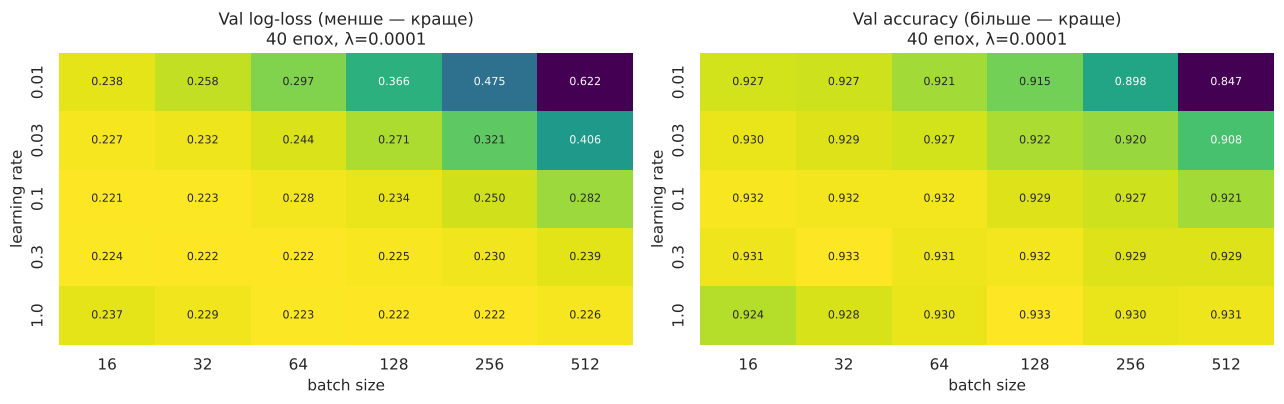

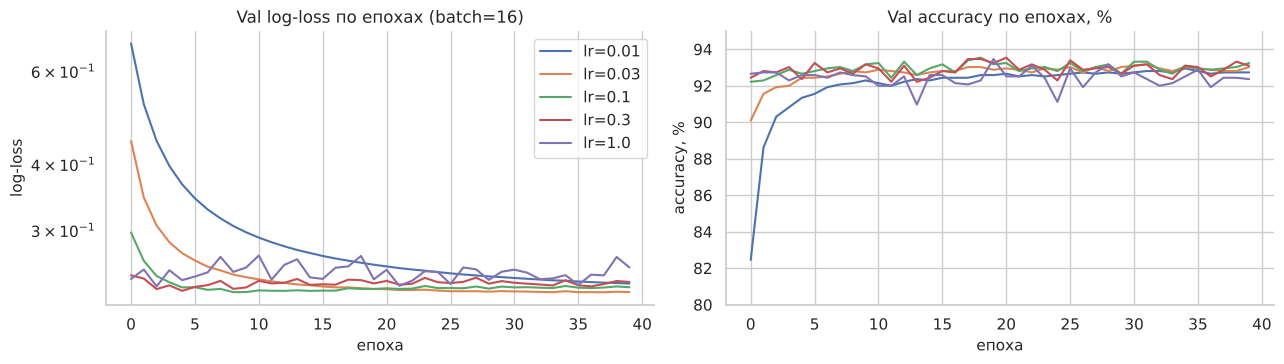

In [12]:
# --- 3.1 Сітка learning rate × batch size (λ фіксовано) ---
LRS = [0.01, 0.03, 0.1, 0.3, 1.0]
BATCHES = [16, 32, 64, 128, 256, 512]
EPOCHS_GRID, LAM_FIXED = 40, 1e-4

t0 = time.time()
grid_rows = []
for lr in LRS:
    for bs in BATCHES:
        mdl = MulticlassLogisticRegression(D, C, lam=LAM_FIXED)
        mdl.fit(X_pool, Y_pool, lr=lr, batch_size=bs, epochs=EPOCHS_GRID, seed=0, track=False)
        r = evaluate(mdl, X_val, y_val)
        grid_rows.append({"lr": lr, "batch": bs, **r})
grid = pd.DataFrame(grid_rows)
print(f"Сітка {len(LRS)}×{len(BATCHES)} за {time.time() - t0:.0f} с")

best = grid.loc[grid["log_loss"].idxmin()]
LR_BEST, BS_BEST = float(best["lr"]), int(best["batch"])
print(f"Найкраща пара за val log-loss: lr = {LR_BEST}, batch = {BS_BEST}  "
      f"(val acc = {best['accuracy']:.4f}, macro-F1 = {best['macro_f1']:.4f}, log-loss = {best['log_loss']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, title, fmt, cmap in [(axes[0], "log_loss", "Val log-loss (менше — краще)", ".3f", "viridis_r"),
                                  (axes[1], "accuracy", "Val accuracy (більше — краще)", ".3f", "viridis")]:
    pv = grid.pivot(index="lr", columns="batch", values=col)
    sns.heatmap(pv, annot=True, fmt=fmt, cmap=cmap, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{title}\n{EPOCHS_GRID} епох, λ={LAM_FIXED:g}"); ax.set_xlabel("batch size"); ax.set_ylabel("learning rate")
plt.tight_layout(); plt.show()

# криві збіжності для різних lr при найкращому batch size
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for lr in LRS:
    mdl = MulticlassLogisticRegression(D, C, lam=LAM_FIXED)
    h = mdl.fit(X_pool, Y_pool, lr=lr, batch_size=BS_BEST, epochs=EPOCHS_GRID, seed=0, X_val=X_val, Y_val=Y_val)
    axes[0].plot(h["val_loss"], label=f"lr={lr}"); axes[1].plot(np.array(h["val_acc"]) * 100, label=f"lr={lr}")
axes[0].set(title=f"Val log-loss по епохах (batch={BS_BEST})", xlabel="епоха", ylabel="log-loss", yscale="log")
axes[1].set(title="Val accuracy по епохах, %", xlabel="епоха", ylabel="accuracy, %", ylim=(80, 95))
axes[0].legend(); plt.tight_layout(); plt.show()

### Висновки: learning rate і batch size

* **Малий lr + великий batch = недонавчання за фіксований бюджет епох.** Для lr = 0.01, batch = 512 за 40 епох виконується лише ≈ 800 оновлень, і val log-loss = 0.62, accuracy = 84.7 %. Кількість кроків за епоху = $m/\text{batch}$, тому при великому батчі потрібен пропорційно більший lr (або більше епох).
* **Широке «плато хорошої якості».** Для lr ∈ [0.1, 0.3] і batch ≤ 128 різниця у val log-loss — у другому–третьому знаку (0.221–0.234), accuracy — 92.9–93.3 %. Модель опукла, тому гіперпараметри лише керують швидкістю збіжності та рівнем шуму SGD, а не «якістю мінімуму».
* **Великий lr = 1.0** дає коливання (права панель кривих: фіолетова лінія коливається в межах ≈ 91–93.5 % між епохами), а з малим батчем (16) — найгірший результат у своєму рядку (0.237): шум градієнта × великий крок.
* **Обрано lr = 0.1, batch = 16** (мін. val log-loss = 0.2214). Слід пам'ятати: малий batch виграє частково тому, що при фіксованих 40 епохах робить *більше оновлень*; ціна — більше кроків на епоху (повільніше обчислення, менше користі від векторизації). Для FL це важливо: локальні клієнти з кількома сотнями прикладів теж зможуть виконати достатньо кроків.

,accuracy,macro_f1,balanced_acc,log_loss,‖W‖_F
λ,,,,,
0.0000e+00,0.9278,0.9384,0.9370,0.2201,13.1792
1.0000e-05,0.9278,0.9384,0.9370,0.2203,13.0515
1.0000e-04,0.9278,0.9385,0.9370,0.2218,12.0888
1.0000e-03,0.9254,0.9352,0.9334,0.2385,8.7043
1.0000e-02,0.9200,0.9284,0.9252,0.3192,4.9893
1.0000e-01,0.8803,0.8890,0.8772,0.6267,2.2235


Мінімум val log-loss = 0.2201 при λ = 0; у межах 1 % — λ ∈ [0.0, 1e-05, 0.0001]
Обрано λ = 0.0001  (val log-loss = 0.2218)


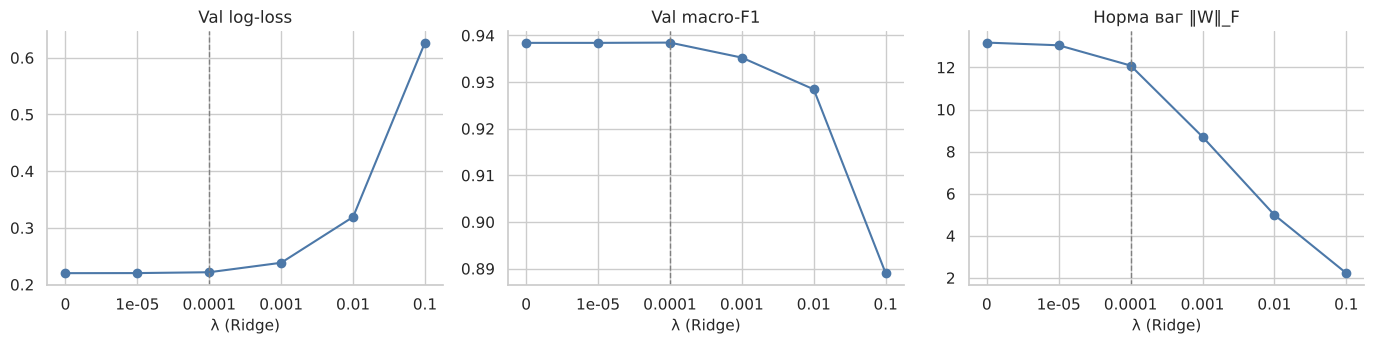

In [13]:
# --- 3.2 Вплив Ridge-регуляризації (λ) ---
LAMS = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
rows = []
for lam in LAMS:
    for s in SEEDS[:3]:
        mdl = MulticlassLogisticRegression(D, C, lam=lam)
        mdl.fit(X_pool, Y_pool, lr=LR_BEST, batch_size=BS_BEST, epochs=60, seed=s, track=False)
        rows.append({"λ": lam, **evaluate(mdl, X_val, y_val), "‖W‖_F": np.linalg.norm(mdl.W)})
lam_df = pd.DataFrame(rows).groupby("λ").mean()
display(lam_df.round(4))

# Правило «найбільша λ у межах 1 % від найкращого val log-loss»: приймаємо різницю, що в межах шуму,
# в обмін на меншу норму ваг (стійкіша модель, обмежений дрейф у FL).
within = lam_df.index[lam_df["log_loss"] <= 1.01 * lam_df["log_loss"].min()]
LAM_BEST = float(max(within))
print(f"Мінімум val log-loss = {lam_df['log_loss'].min():.4f} при λ = {lam_df['log_loss'].idxmin():g}; "
      f"у межах 1 % — λ ∈ {[float(l) for l in within]}")
print(f"Обрано λ = {LAM_BEST:g}  (val log-loss = {lam_df.loc[LAM_BEST, 'log_loss']:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
xs = np.arange(len(LAMS))
for ax, col, title in zip(axes, ["log_loss", "macro_f1", "‖W‖_F"],
                          ["Val log-loss", "Val macro-F1", "Норма ваг ‖W‖_F"]):
    ax.plot(xs, lam_df[col].values, "o-", color="#4C78A8")
    ax.set_xticks(xs); ax.set_xticklabels(["0" if l == 0 else f"{l:g}" for l in LAMS])
    ax.set_xlabel("λ (Ridge)"); ax.set_title(title)
    ax.axvline(LAMS.index(LAM_BEST), color="gray", ls="--", lw=1)
plt.tight_layout(); plt.show()

### Висновки: Ridge-регуляризація

| λ | 0 | 1e-5 | **1e-4** | 1e-3 | 1e-2 | 1e-1 |
|---|---|---|---|---|---|---|
| val log-loss | 0.2201 | 0.2203 | **0.2218** | 0.2385 | 0.3192 | 0.6267 |
| ‖W‖_F | 13.2 | 13.1 | **12.1** | 8.7 | 5.0 | 2.2 |

* **Регуляризація тут не покращує якість**: мінімум val log-loss — при λ = 0. Причина зрозуміла: прикладів $m\approx10^4$ значно більше, ніж параметрів (119), тож модель не перенавчається за дисперсією; Ridge додає лише **зсув** (bias). Для λ ≥ 10⁻³ це вже недонавчання: log-loss зростає на 8 % → 45 % → 185 %, а при λ = 0.1 accuracy падає до 88 %.
* Чому штраф зменшує норму ваг: градієнт $\lambda W$ тягне ваги до нуля («weight decay»); ваги стискаються плавно (норма 13.2 → 2.2), але не обнуляються (на відміну від Lasso).
* **Рішення:** за правилом «найбільша λ у межах 1 % від найкращого val log-loss» обрано **λ = 10⁻⁴**. Різниця (0.2218 проти 0.2201) лежить у межах шуму, accuracy і macro-F1 не змінюються (0.9278 / 0.9385), а ваги стають на ≈ 8 % меншими, тобто Ridge лишається активним компонентом пайплайна «безкоштовно». Чесний висновок: на цьому датасеті Ridge — це «страховка», а не джерело виграшу.

Обрані гіперпараметри: {'lr': 0.1, 'batch_size': 16, 'lam': 0.0001} | епох: 100 | ознак: 16


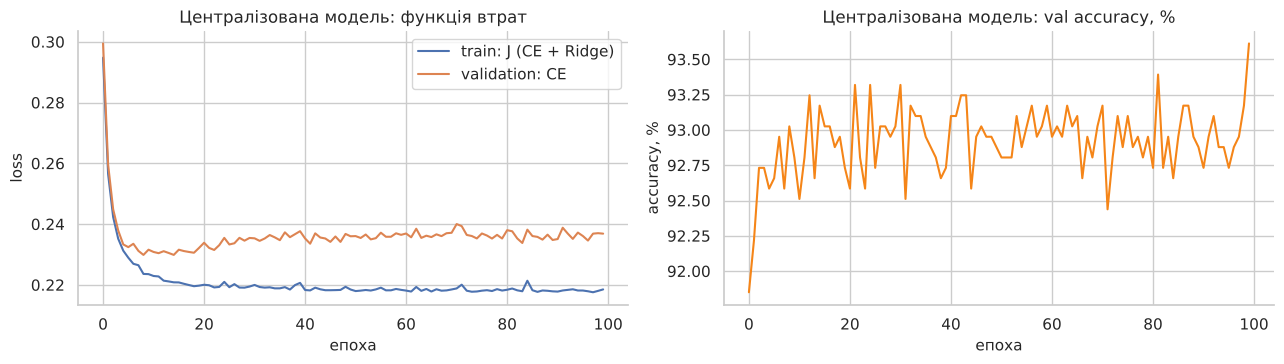

Мін. val CE = 0.2299 (епоха 9); на епосі 100: val CE = 0.2369, train J = 0.2185; val acc: мін/макс за епохи 0.9185/0.9361


,accuracy,macro_f1,balanced_acc,log_loss
Global Validation,0.9361,0.9455,0.9432,0.2215
Global Test,0.9212,0.9350,0.9340,0.2124


In [14]:
# --- 3.3 Фінальне навчання централізованої моделі + оцінка на Global Test ---
HP = dict(lr=LR_BEST, batch_size=BS_BEST, lam=LAM_BEST)
EPOCHS_CENTRAL = 100
print("Обрані гіперпараметри:", HP, "| епох:", EPOCHS_CENTRAL, "| ознак:", D)

central = MulticlassLogisticRegression(D, C, lam=HP["lam"])
hist_c = central.fit(X_pool, Y_pool, lr=HP["lr"], batch_size=HP["batch_size"], epochs=EPOCHS_CENTRAL,
                     seed=SEED, X_val=X_val, Y_val=Y_val)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(hist_c["train_loss"], label="train: J (CE + Ridge)")
axes[0].plot(hist_c["val_loss"], label="validation: CE")
axes[0].set(title="Централізована модель: функція втрат", xlabel="епоха", ylabel="loss"); axes[0].legend()
axes[1].plot(np.array(hist_c["val_acc"]) * 100, color="#F58518")
axes[1].set(title="Централізована модель: val accuracy, %", xlabel="епоха", ylabel="accuracy, %")
plt.tight_layout(); plt.show()

best_ep = int(np.argmin(hist_c["val_loss"]))
print(f"Мін. val CE = {hist_c['val_loss'][best_ep]:.4f} (епоха {best_ep + 1}); на епосі {EPOCHS_CENTRAL}: val CE = {hist_c['val_loss'][-1]:.4f}, "
      f"train J = {hist_c['train_loss'][-1]:.4f}; val acc: мін/макс за епохи {min(hist_c['val_acc']):.4f}/{max(hist_c['val_acc']):.4f}")
central_val = evaluate(central, X_val, y_val)
central_test = evaluate(central, X_test, y_test)          # ЄДИНА фінальна оцінка на Global Test
display(pd.DataFrame({"Global Validation": central_val, "Global Test": central_test}).T.round(4))

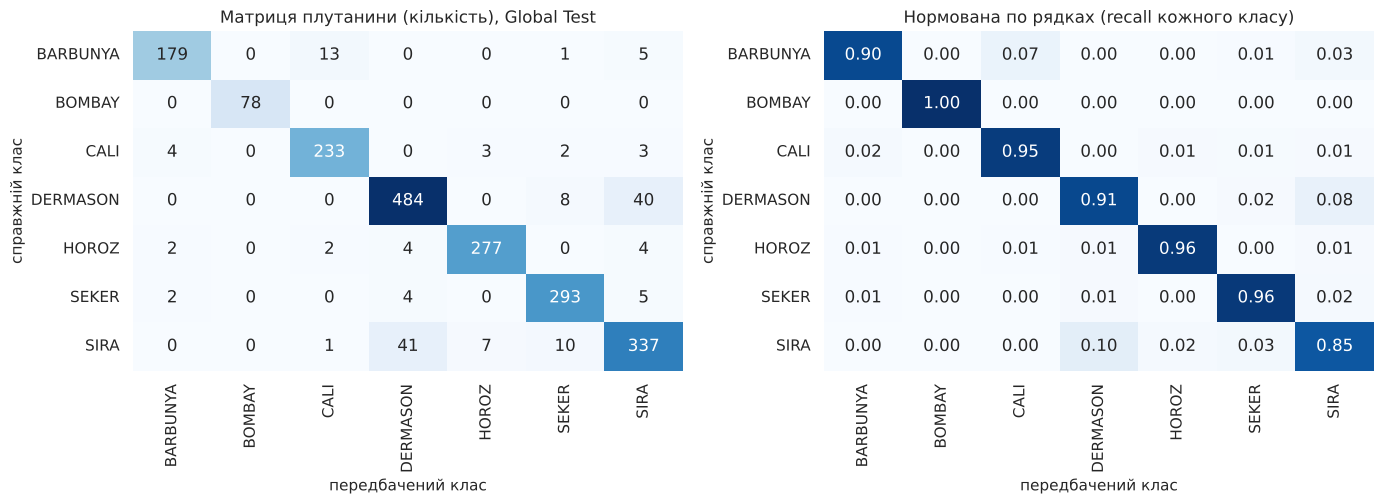

,precision,recall,support
BARBUNYA,0.957,0.904,198
BOMBAY,1.000,1.000,78
CALI,0.936,0.951,245
DERMASON,0.908,0.910,532
HOROZ,0.965,0.958,289
SEKER,0.933,0.964,304
SIRA,0.855,0.851,396


Найчастіші помилки (справжній → передбачений): ['SIRA → DERMASON: 41', 'DERMASON → SIRA: 40', 'BARBUNYA → CALI: 13']


In [15]:
# матриця плутанини та по-класові precision / recall (на Global Test)
cm = confusion_matrix(y_test, central.predict(X_test), labels=np.arange(C))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False, ax=axes[0])
axes[0].set(title="Матриця плутанини (кількість), Global Test", xlabel="передбачений клас", ylabel="справжній клас")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=classes, yticklabels=classes, cbar=False, ax=axes[1])
axes[1].set(title="Нормована по рядках (recall кожного класу)", xlabel="передбачений клас", ylabel="справжній клас")
plt.tight_layout(); plt.show()

per_class = pd.DataFrame({"precision": np.diag(cm) / cm.sum(axis=0), "recall": np.diag(cm) / cm.sum(axis=1),
                          "support": cm.sum(axis=1)}, index=classes)
display(per_class.round(3))

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:3], off.shape))[0]
print("Найчастіші помилки (справжній → передбачений):",
      [f"{classes[i]} → {classes[j]}: {off[i, j]}" for i, j in top])

### Висновки: централізована модель

* **Результат на Global Test (одноразова оцінка):** accuracy = **0.9212**, macro-F1 = **0.9350**, balanced accuracy = **0.9340**, log-loss = **0.2124**. Значення на валідації вищі (accuracy 0.9361): частково через вибіркову варіацію (1 362 прикладів → стандартна похибка ≈ 0.7 п.п.), частково через те, що гіперпараметри *підбиралися* саме на валідації (невеликий оптимізм). Тест — чесніша оцінка.
* **Криві навчання.** Train-втрата $J$ монотонно спадає (до 0.2185), валідаційна CE досягає мінімуму 0.2299 вже на 9-й епосі й повільно дрейфує до 0.2369 на 100-й; val accuracy коливається в межах 91.9–93.6 % — це шум константного-lr SGD з batch = 16, а не збіжність до іншого розв'язку. Тобто модель вийшла на плато за ≈ 10–20 епох; 100 епох — «з запасом» (зручно, бо порівнюємо з FL, де сумарне навчання теж велике), а легке зростання val-loss — ознака дуже слабкого перенавчання, яке лікується early stopping або більшим λ.
* **Матриця плутанини.** **Bombay розпізнається ідеально** (precision = recall = 1.00; найбільші зерна, найвиразніший клас), добре — Horoz, Seker, Cali (recall 0.95–0.96). Основні помилки — **Sira ↔ Dermason** (41 і 40 хибних відповідей; recall Sira = 0.85, precision = 0.855 — найслабший клас) та Barbunya → Cali (13). Це схожі за формою сорти, межа між якими не є лінійною в 16-вимірному просторі ознак — тому лінійна модель має «стелю» ≈ 92 %. macro-F1 (0.935) вищий за accuracy (0.921), бо accuracy зважує за частотою, а найчисельніші Dermason і Sira — найскладніші, тоді як рідкісний Bombay розпізнається ідеально.
* Ця модель — **верхній орієнтир** для всіх FL-експериментів нижче (та сама архітектура, ті самі гіперпараметри, ті самі дані).

---
# Етап 4. Розподіл даних між клієнтами та сервером

## 4.1 Архітектура та принципи доступу

| | Сервер (агрегатор) | Клієнт $k$ |
|---|---|---|
| **бачить** | Global Test, Global Validation, ваги, які повертають клієнти | лише власну $D_k$ ⊂ FL Train Pool |
| **НЕ бачить** | сирі дані клієнтів, локальні вибірки | Global Test, Global Validation, дані та ваги інших клієнтів (лише глобальну модель від сервера) |

Схема розподілу (Етап 4) і раунду (Етап 5):

```
FL Train Pool ──(partition: IID / Dirichlet(α))──►  D₁   D₂   D₃   D₄   D₅      (n_k = |D_k|, Σ n_k = |Pool|)
                                                    │    │    │    │    │
   раунд t:  сервер ──── w^t ───────────────────────┴────┴────┴────┴────┘   (розсилка глобальної моделі)
             клієнти: E локальних епох SGD від w^t  →  w_k^{t+1}
             сервер ◄─── w_k^{t+1} ─────────────────────────────────────    (повертаються лише ваги)
             w^{t+1} = Σ_k (n_k / Σ n_j) · w_k^{t+1}                         (FedAvg)
             оцінка w^{t+1} на Global Validation; Global Test — лише наприкінці
```

**Вимоги до розподілу (перевіряються кодом):** кожен приклад належить рівно одному клієнту; розподіл задокументований (кількість клієнтів, $n_k$, розподіл класів); розподіл відтворюваний (фіксований seed).

## 4.2 Реалізація розподілів

* **IID (стратифікований):** приклади кожного класу перемішуються й ділляться на $K$ майже рівних частин → кожен клієнт отримує ≈ глобальні пропорції класів.
* **Non-IID (Діріхле):** для кожного класу $c$ генеруємо $(p_{1c},\dots,p_{Kc})\sim\mathrm{Dir}(\alpha,\dots,\alpha)$ і розподіляємо приклади цього класу між клієнтами за цими пропорціями. Мале $\alpha$ → пропорції «гострі», клас майже весь потрапляє до 1–2 клієнтів; велике $\alpha$ → пропорції ≈ $1/K$ (близько до IID).
* Щоб не отримати клієнтів із пренебрежно малою кількістю прикладів, генерація **повторюється** (з наступними випадковими числами того самого генератора), доки найменший клієнт не матиме ≥ `min_size` = 10 прикладів.

In [16]:
K_CLIENTS = 5
MIN_CLIENT_SIZE = 10


def iid_partition(y, K, seed=0):
    """Стратифікований IID: кожен клас перемішується і ділиться на K майже рівних частин."""
    rng = np.random.default_rng(seed)
    client_idx = [[] for _ in range(K)]
    for c in range(int(y.max()) + 1):                         # цикл по КЛАСАХ
        idx_c = rng.permutation(np.where(y == c)[0])
        for k, chunk in enumerate(np.array_split(idx_c, K)):
            client_idx[(k + c) % K].extend(chunk.tolist())    # зсув (k+c), щоб «зайві» приклади не діставались одному клієнту
    return [np.sort(np.array(ci, dtype=int)) for ci in client_idx]


def dirichlet_partition(y, K, alpha, seed=0, min_size=MIN_CLIENT_SIZE, max_tries=1000, return_tries=False):
    """Non-IID розподіл за Діріхле: для кожного класу p ~ Dir(α·1_K), приклади класу ділимо за p."""
    rng = np.random.default_rng(seed)
    n_classes = int(y.max()) + 1
    for tries in range(1, max_tries + 1):
        client_idx = [[] for _ in range(K)]
        for c in range(n_classes):                            # цикл по КЛАСАХ
            idx_c = rng.permutation(np.where(y == c)[0])
            p = rng.dirichlet(alpha * np.ones(K))             # частки класу c для K клієнтів
            cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx_c, cuts)):
                client_idx[k].extend(chunk.tolist())
        if min(len(ci) for ci in client_idx) >= min_size:     # захист від клієнтів майже без даних
            break
    else:
        raise RuntimeError("не вдалося отримати розподіл з min_size; збільште max_tries або зменште min_size")
    parts = [np.sort(np.array(ci, dtype=int)) for ci in client_idx]
    return (parts, tries) if return_tries else parts


def make_partition(kind, y, K, seed=0):
    """kind = "iid" або число α (Діріхле)."""
    return iid_partition(y, K, seed) if kind == "iid" else dirichlet_partition(y, K, kind, seed)


def partition_table(parts, y):
    """Документація розподілу: кількість прикладів та розподіл класів у кожного клієнта."""
    t = pd.DataFrame([np.bincount(y[p], minlength=C) for p in parts], columns=classes,
                     index=[f"клієнт {k + 1}" for k in range(len(parts))])
    t.insert(0, "n_k", t.sum(axis=1))
    return t


def label_skew(parts, y):
    """Міра неоднорідності: середня (зважена за n_k) total-variation відстань між розподілом класів клієнта й глобальним (0 = IID)."""
    glob = np.bincount(y, minlength=C) / len(y)
    tv = [0.5 * np.abs(np.bincount(y[p], minlength=C) / len(p) - glob).sum() for p in parts]
    return float(np.average(tv, weights=[len(p) for p in parts]))


def validate_partition(parts, n_total):
    """Кожен приклад — рівно в одного клієнта; повертає (мін., макс. n_k)."""
    all_idx = np.sort(np.concatenate(parts))
    assert np.array_equal(all_idx, np.arange(n_total)), "приклад втрачено або продубльовано!"
    sizes = [len(p) for p in parts]
    return min(sizes), max(sizes)


# --- самоперевірки ---
for kind in ["iid", 5, 1, 0.3]:
    p1, p2 = make_partition(kind, y_pool, K_CLIENTS, seed=7), make_partition(kind, y_pool, K_CLIENTS, seed=7)
    assert all(np.array_equal(u, v) for u, v in zip(p1, p2)), "розподіл невідтворюваний"
    mn, mx = validate_partition(p1, len(y_pool))
    print(f"{str(kind):>4}: покриття повне, відтворюваний ✓ | n_k від {mn} до {mx} | label-skew = {label_skew(p1, y_pool):.3f}")

 iid: покриття повне, відтворюваний ✓ | n_k від 2041 до 2043 | label-skew = 0.001
   5: покриття повне, відтворюваний ✓ | n_k від 1367 до 2626 | label-skew = 0.164
   1: покриття повне, відтворюваний ✓ | n_k від 900 до 3058 | label-skew = 0.280
 0.3: покриття повне, відтворюваний ✓ | n_k від 858 до 3280 | label-skew = 0.440


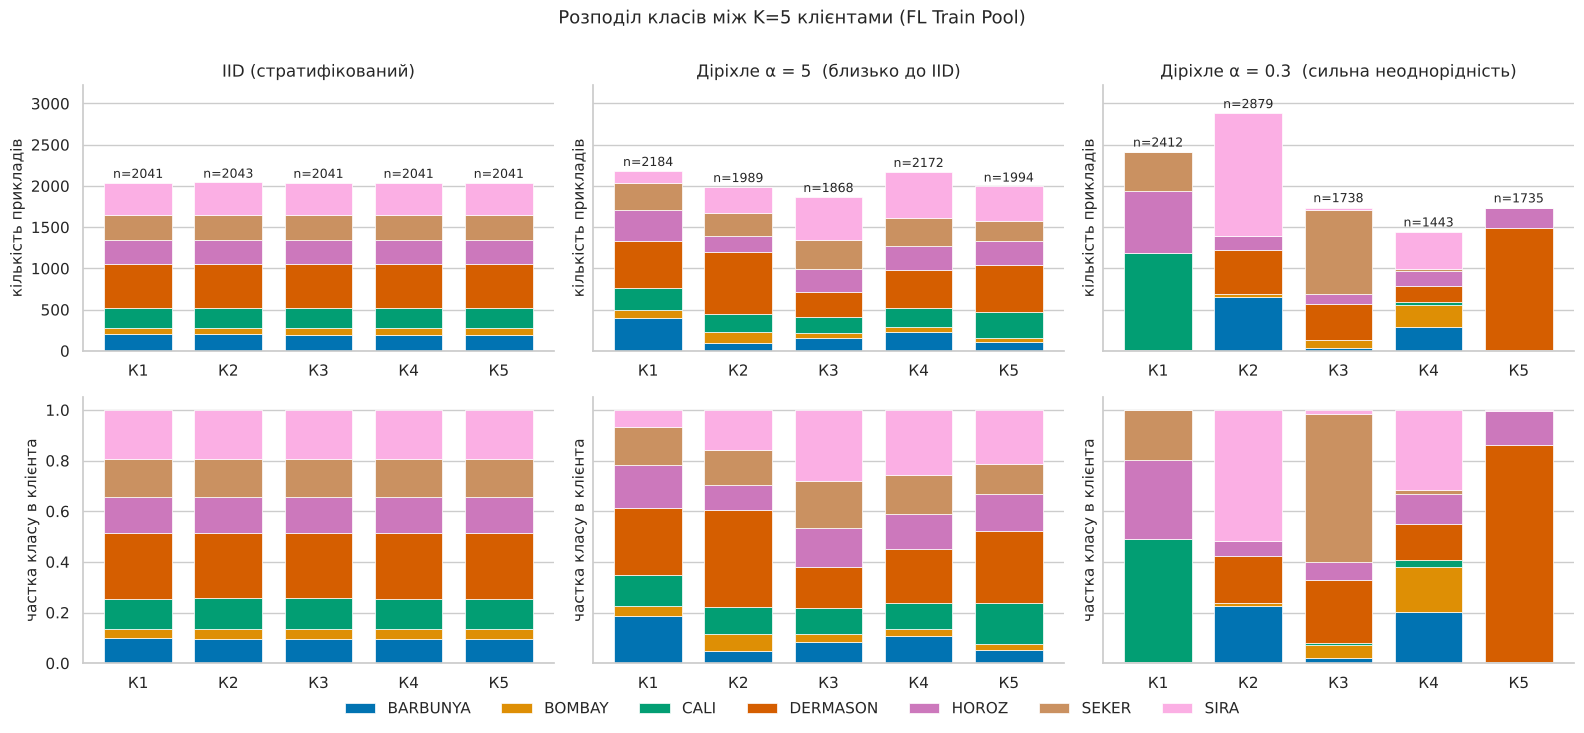


=== Діріхле α = 5  (близько до IID) ===


,n_k,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
клієнт 1,2184,404,93,264,574,372,328,149
клієнт 2,1989,98,129,218,758,195,276,315
клієнт 3,1868,154,63,190,303,287,344,527
клієнт 4,2172,233,56,227,460,301,335,560
клієнт 5,1994,103,51,323,564,291,237,425



=== Діріхле α = 0.3  (сильна неоднорідність) ===


,n_k,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
клієнт 1,2412,7,5,1174,0,747,477,2
клієнт 2,2879,651,37,0,533,172,1,1485
клієнт 3,1738,35,91,9,439,118,1015,31
клієнт 4,1443,292,258,38,204,171,26,454
клієнт 5,1735,7,1,1,1483,238,1,4


In [17]:
def plot_partition(parts, y, title, ax_counts, ax_share):
    cnt = np.stack([np.bincount(y[p], minlength=C) for p in parts])          # (K, C)
    pal = sns.color_palette("colorblind", C)
    x = np.arange(len(parts))
    for ax, data, ylabel in [(ax_counts, cnt, "кількість прикладів"), (ax_share, cnt / cnt.sum(1, keepdims=True), "частка класу в клієнта")]:
        bottom = np.zeros(len(parts))
        for c in range(C):
            ax.bar(x, data[:, c], bottom=bottom, color=pal[c], label=classes[c], width=0.75, edgecolor="white", linewidth=0.5)
            bottom += data[:, c]
        ax.set_xticks(x); ax.set_xticklabels([f"К{k + 1}" for k in x]); ax.set_ylabel(ylabel); ax.grid(axis="x", visible=False)
    for xi, n in zip(x, cnt.sum(1)):
        ax_counts.text(xi, n + cnt.sum(1).max() * 0.01, f"n={n}", ha="center", va="bottom", fontsize=9)
    ax_counts.set_ylim(0, cnt.sum(1).max() * 1.12)
    ax_counts.set_title(title)


scenarios = [("IID (стратифікований)", "iid"), ("Діріхле α = 5  (близько до IID)", 5), ("Діріхле α = 0.3  (сильна неоднорідність)", 0.3)]
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey="row")
for j, (title, kind) in enumerate(scenarios):
    parts_demo = make_partition(kind, y_pool, K_CLIENTS, seed=SEED)
    plot_partition(parts_demo, y_pool, title, axes[0, j], axes[1, j])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=C, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Розподіл класів між K=5 клієнтами (FL Train Pool)", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

for title, kind in scenarios[1:]:
    print(f"\n=== {title} ===")
    pt = partition_table(make_partition(kind, y_pool, K_CLIENTS, seed=SEED), y_pool)
    display(pt)

In [18]:
# перевірка «клієнтів з надто малою кількістю прикладів» для різних α (5 різних seed)
rows = []
for alpha in [5, 1, 0.3, 0.1]:
    for s in SEEDS:
        parts_s, tries = dirichlet_partition(y_pool, K_CLIENTS, alpha, seed=s, min_size=1, return_tries=True)
        raw_min = min(len(p) for p in parts_s)
        rows.append({"α": alpha, "seed": s, "мін. n_k": raw_min, "макс. n_k": max(len(p) for p in parts_s),
                     "label-skew": label_skew(parts_s, y_pool)})
chk = pd.DataFrame(rows).groupby("α", sort=False).agg({"мін. n_k": ["min", "mean"], "макс. n_k": "max", "label-skew": "mean"})
display(chk.round(3))
print(f"Поріг для 'надто малого' клієнта: {MIN_CLIENT_SIZE} прикладів. У коді розподіл перегенеровується, доки мінімум не стане ≥ {MIN_CLIENT_SIZE}.")

мін. n_k         макс. n_k label-skew
         min    mean       max       mean
α                                        
5.0     1541  1698.4      2814      0.141
1.0      610  1324.2      3414      0.276
0.3      176   564.8      4505      0.446
0.1       91   480.6      4057      0.601

Поріг для 'надто малого' клієнта: 10 прикладів. У коді розподіл перегенеровується, доки мінімум не стане ≥ 10.


### Висновки Етапу 4

* **IID:** кожен клієнт має 2 041–2 043 прикладів і майже ідентичні частки класів (label-skew ≈ 0.001).
* **α = 5 (seed 42):** розміри 1 868–2 184, усі 7 класів присутні в усіх клієнтів, частки класів відрізняються помірно (label-skew, середнє за 5 seed-ів, ≈ 0.14). Практично IID.
* **α = 0.3:** розміри 1 443–2 879; склад клієнтів радикально різний: клієнт 5 складається на 85 % з Dermason (1 483 з 1 735), у клієнта 1 — майже лише Cali, Horoz і Seker (Dermason — 0, Bombay — 5, Sira — 2), у клієнта 2 немає жодного Cali, а Bombay сконцентровано в клієнта 4. Mean label-skew ≈ 0.45 (для α = 1 — 0.28, для α = 0.1 — 0.60): відстань між розподілом класів клієнта і глобальним монотонно зростає при зменшенні α, тож α — зручна «ручка неоднорідності».
* **Малі клієнти.** Найменший клієнт за 5 seed-ів має 176 прикладів при α = 0.3 і 91 при α = 0.1 — тобто «надто малих» (< 10) немає навіть без страхувальної перегенерації; перевірку `min_size = 10` залишено у коді як гарантію.
* **Як це впливає на глобальну модель.** Кожен клієнт мінімізує *свою* втрату $F_k$, а клієнт, у якого класу немає, активно «розучує» його (логіти відсутнього класу штовхаються вниз). Чим сильніша неоднорідність, тим більше локальні мінімуми $w_k^\*$ відрізняються від глобального $w^\*$, і тим складніше усереднення їх узгодить — докладний аналіз у Етапі 6.
* Коректність перевірена кодом: кожен приклад належить рівно одному клієнту, розподіл відтворюваний (однаковий seed → однакові індекси), розподіл задокументований таблицями $n_k$ і кількості по класах.

---
# Етап 5. Симуляція федеративного навчання (FedAvg)

## 5.1 Алгоритм

1. Сервер ініціалізує глобальну модель $w^0$ (нульові $W,b$ — однакова для всіх).
2. На раунді $t$ сервер обирає підмножину клієнтів $S_t$ (тут за замовчуванням — усі $K=5$; параметр `participation` дозволяє частку < 1).
3. Сервер передає $w^t$ обраним клієнтам.
4. Кожен клієнт $k\in S_t$ виконує **$E$ локальних епох** міні-батчевого GD, починаючи з $w^t$, на **власних** даних $D_k$.
5. Клієнт повертає лише параметри $w_k^{t+1}=(W_k,b_k)$ та $n_k$.
6. Сервер агрегує: $$w^{t+1}=\sum_{k\in S_t}\frac{n_k}{\sum_{j\in S_t}n_j}\,w_k^{t+1}$$ — і для $W$, і для $b$.
7. Глобальна модель оцінюється на **Global Validation** (Global Test — лише наприкінці).

Архітектурно сервер і клієнти розділені: клас `Client` володіє своїми даними й віддає назовні **тільки ваги та $n_k$**; функція `fedavg_aggregate` приймає лише ваги й розміри — сирих даних сервер не бачить. Для відстеження *client drift* на кожному раунді також вимірюємо розкид клієнтських моделей навколо нової глобальної:
$$\mathrm{drift}_t=\sum_k \frac{n_k}{\sum_j n_j}\,\bigl\lVert w_k^{t+1}-w^{t+1}\bigr\rVert_F .$$

**Чому зважувати за $n_k$?** Глобальна ціль — мінімізувати емпіричний ризик **на всіх даних**: $F(w)=\sum_k \frac{n_k}{n}F_k(w)$, де $F_k$ — середня втрата клієнта $k$. Саме з вагами $n_k/n$ агрегована модель є (у випадку одного кроку градієнта) еквівалентом централізованого кроку по всіх даних. Прості середні (вага $1/K$) надають клієнту з 50 прикладами такий самий вплив, як клієнту з 5 000, — оцінка стає зміщеною й дуже шумною; див. експеримент 5.3.

In [19]:
class Client:
    """Клієнт FL: володіє ЛИШЕ своїми даними D_k. Назовні віддає тільки оновлені ваги та n_k."""

    def __init__(self, cid, X, Y):
        self.cid, self.X, self.Y, self.n = cid, X, Y, len(X)

    def local_update(self, global_params, epochs, lr, batch_size, lam, seed):
        model = MulticlassLogisticRegression(self.X.shape[1], self.Y.shape[1], lam)
        model.set_params(*global_params)                       # старт з глобальної моделі w^t
        model.fit(self.X, self.Y, lr=lr, batch_size=batch_size, epochs=epochs, seed=seed, track=False)
        return model.get_params(), self.n                      # лише (W, b) та n_k


def make_clients(parts, X=None, Y=None):
    X = X_pool if X is None else X
    Y = Y_pool if Y is None else Y
    return [Client(k, X[p], Y[p]) for k, p in enumerate(parts)]


def fedavg_aggregate(params_list, sizes, weighted=True):
    """Серверна агрегація: w = Σ_k (n_k/Σn_j) · w_k  (векторизовано, без циклів по клієнтах).
    weighted=False → просте середнє (для порівняння)."""
    sizes = np.asarray(sizes, dtype=float)
    coef = sizes / sizes.sum() if weighted else np.full(len(sizes), 1.0 / len(sizes))
    Ws = np.stack([p[0] for p in params_list])                 # (K, d, C)
    bs = np.stack([p[1] for p in params_list])                 # (K, 1, C)
    return np.tensordot(coef, Ws, axes=1), np.tensordot(coef, bs, axes=1)


def run_fedavg(clients, rounds, local_epochs, lr, batch_size, lam, X_val, Y_val,
               participation=1.0, weighted=True, seed=0):
    """Серверний цикл FedAvg. Повертає глобальну модель та історію по раундах (на Global Validation)."""
    rng = np.random.default_rng(seed)
    d, n_classes = clients[0].X.shape[1], clients[0].Y.shape[1]
    server = MulticlassLogisticRegression(d, n_classes, lam)    # w⁰
    y_val_int = Y_val.argmax(1)
    hist = {"val_acc": [], "val_loss": [], "val_f1": [], "drift": []}

    for t in range(rounds):                                     # цикл по раундах
        n_sel = max(1, int(round(participation * len(clients))))
        selected = rng.choice(len(clients), n_sel, replace=False)          # S_t
        w_t = server.get_params()
        updates, sizes = [], []
        for k in selected:                                      # цикл по клієнтах (локальне навчання)
            p, n = clients[k].local_update(w_t, local_epochs, lr, batch_size, lam, seed=int(rng.integers(1 << 30)))
            updates.append(p); sizes.append(n)

        W_new, b_new = fedavg_aggregate(updates, sizes, weighted)           # агрегація на сервері
        server.set_params(W_new, b_new)

        coef = np.asarray(sizes, float) / np.sum(sizes)
        spread = [np.sqrt(np.sum((p[0] - W_new) ** 2) + np.sum((p[1] - b_new) ** 2)) for p in updates]
        hist["drift"].append(float(np.dot(coef, spread)))
        pred = server.predict(X_val)
        hist["val_acc"].append(float(np.mean(pred == y_val_int)))
        hist["val_f1"].append(f1_score(y_val_int, pred, average="macro"))
        hist["val_loss"].append(float(server.cross_entropy(X_val, Y_val)))
    return server, hist


def train_local_models(clients, epochs, hp, seed=0):
    """«Локальні клієнтські моделі»: кожна навчається ЛИШЕ на даних свого клієнта (без обміну)."""
    models = []
    for c in clients:
        m = MulticlassLogisticRegression(c.X.shape[1], c.Y.shape[1], hp["lam"])
        m.fit(c.X, c.Y, lr=hp["lr"], batch_size=hp["batch_size"], epochs=epochs, seed=seed + c.cid, track=False)
        models.append(m)
    return models


# ---------- самоперевірка агрегації ----------
rng = np.random.default_rng(1)
ps = [(rng.normal(size=(D, C)), rng.normal(size=(1, C))) for _ in range(3)]
ns = [10, 30, 60]
Wg, bg = fedavg_aggregate(ps, ns)
W_manual = sum(n / 100 * p[0] for n, p in zip(ns, ps)); b_manual = sum(n / 100 * p[1] for n, p in zip(ns, ps))
assert np.allclose(Wg, W_manual) and np.allclose(bg, b_manual)
Wu, _ = fedavg_aggregate(ps, ns, weighted=False)
assert np.allclose(Wu, sum(p[0] for p in ps) / 3)
assert np.allclose(fedavg_aggregate(ps, [5, 5, 5])[0], Wu)        # рівні n_k ⇒ зважене = просте
print("✓ агрегація: зважене середнє збігається з ручним розрахунком; при рівних n_k збігається з простим")

✓ агрегація: зважене середнє збігається з ручним розрахунком; при рівних n_k збігається з простим


Гіперпараметри клієнтів (з централізованого підбору): {'lr': 0.1, 'batch_size': 16, 'lam': 0.0001} | раундів: 50
Прогін FedAvg (50 раундів) за 4.1 с; розміри клієнтів n_k = [3221, 2250, 3438, 1122, 176]


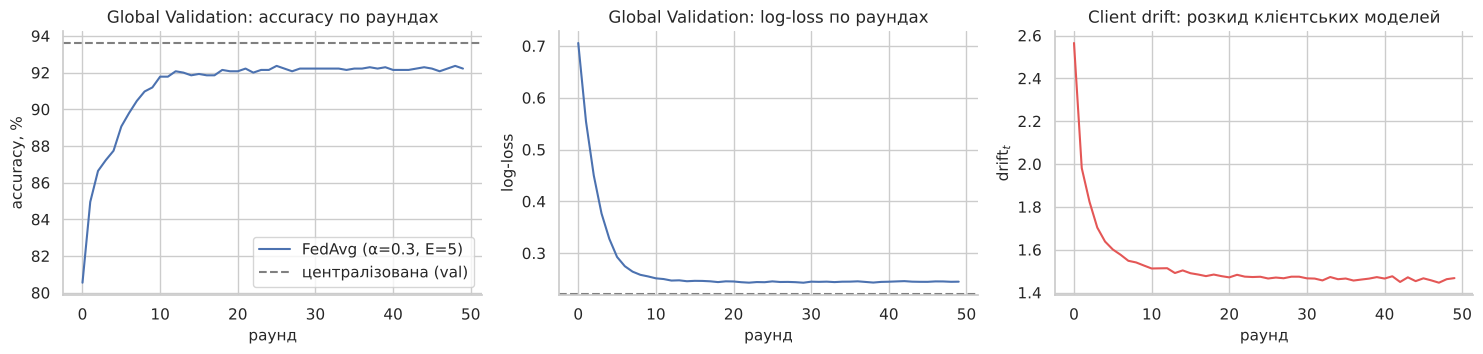

Фінальні метрики FedAvg на Global Test (одноразова оцінка): {'accuracy': 0.9182, 'macro_f1': 0.9337, 'balanced_acc': 0.9321, 'log_loss': 0.2248}


In [20]:
ROUNDS = 50                 # кількість раундів зв'язку
E_DEFAULT = 5               # локальних епох за замовчуванням (Експеримент 1)
print("Гіперпараметри клієнтів (з централізованого підбору):", HP, "| раундів:", ROUNDS)


def run_scenario(kind, E, seed, K_cl=K_CLIENTS, rounds=ROUNDS, weighted=True, participation=1.0, local_baseline=False):
    """Повний прогін: розподіл → клієнти → FedAvg → (опційно) локальні моделі. Global Test — лише наприкінці."""
    parts = make_partition(kind, y_pool, K_cl, seed)
    clients = make_clients(parts)
    server, hist = run_fedavg(clients, rounds, E, HP["lr"], HP["batch_size"], HP["lam"], X_val, Y_val,
                              participation=participation, weighted=weighted, seed=seed)
    res = {"kind": kind, "E": E, "seed": seed, "hist": hist, "sizes": [c.n for c in clients],
           "skew": label_skew(parts, y_pool), "test": evaluate(server, X_test, y_test), "parts": parts, "server": server}
    if local_baseline:                                          # той самий обчислювальний бюджет: rounds·E епох
        locs = train_local_models(clients, rounds * E, HP, seed=seed)
        res["local"] = [evaluate(m, X_test, y_test) for m in locs]
    return res


# ---------- демонстраційний прогін: α = 0.3, E = 5 ----------
t0 = time.time()
demo = run_scenario(0.3, E_DEFAULT, seed=0)
print(f"Прогін FedAvg ({ROUNDS} раундів) за {time.time() - t0:.1f} с; розміри клієнтів n_k = {demo['sizes']}")

h = demo["hist"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
axes[0].plot(np.array(h["val_acc"]) * 100, label="FedAvg (α=0.3, E=5)")
axes[0].axhline(central_val["accuracy"] * 100, color="gray", ls="--", label="централізована (val)")
axes[0].set(title="Global Validation: accuracy по раундах", xlabel="раунд", ylabel="accuracy, %"); axes[0].legend()
axes[1].plot(h["val_loss"]); axes[1].axhline(central_val["log_loss"], color="gray", ls="--")
axes[1].set(title="Global Validation: log-loss по раундах", xlabel="раунд", ylabel="log-loss")
axes[2].plot(h["drift"], color="#E45756")
axes[2].set(title="Client drift: розкид клієнтських моделей", xlabel="раунд", ylabel=r"drift$_t$")
plt.tight_layout(); plt.show()
print("Фінальні метрики FedAvg на Global Test (одноразова оцінка):", {k: round(v, 4) for k, v in demo["test"].items()})

### Висновок щодо демонстраційного прогону (α = 0.3, E = 5, seed 0)

* **Збіжність.** Val accuracy зростає з ≈ 80.6 % після 1-го раунду до ≈ 92 % за ≈ 12 раундів і далі виходить на плато ≈ 92.2 %, що **трохи нижче за централізовану модель** (штрихова лінія, 93.6 % на val); val log-loss стабілізується на ≈ 0.245 проти 0.22 у централізованої. Фінальні метрики на Global Test: accuracy = 0.9182, macro-F1 = 0.9337, log-loss = 0.2248 (централізована: 0.9212 / 0.9350 / 0.2124).
* **Client drift** (права панель) різко падає в перших раундах (модель ще не навчена, локальні градієнти великі), але **виходить на стабільне ненульове плато ≈ 1.45–1.5**: клієнти ніколи не узгоджуються повністю, бо їхні локальні цілі різні. Це і є вимірюваний «дрейф» — розкид локальних моделей навколо глобальної після $E$ епох.

In [21]:
# --- 5.3 Зважена агрегація проти простого середнього (α = 0.3 та екстремальніше α = 0.1; 5 розбиттів) ---
rows = []
for alpha in [0.3, 0.1]:
    for s in SEEDS:
        for weighted in (True, False):
            r = run_scenario(alpha, E_DEFAULT, s, weighted=weighted)
            rows.append({"α": alpha, "агрегація": "зважена за n_k" if weighted else "просте середнє", "seed": s,
                         "n_k min/max": f"{min(r['sizes'])}/{max(r['sizes'])}", **r["test"]})
agg_raw = pd.DataFrame(rows)
agg_cmp = agg_raw.drop(columns=["seed", "n_k min/max"]).groupby(["α", "агрегація"], sort=False).agg(["mean", "std"])
display(agg_cmp.round(4))

accuracy         macro_f1         balanced_acc         log_loss        
                       mean     std     mean     std         mean     std     mean     std
α   агрегація                                                                             
0.3 зважена за n_k   0.9156  0.0037   0.9296  0.0048       0.9294  0.0047   0.2308  0.0087
    просте середнє   0.9131  0.0052   0.9282  0.0048       0.9290  0.0053   0.2374  0.0105
0.1 зважена за n_k   0.8944  0.0164   0.9088  0.0169       0.9097  0.0188   0.2980  0.0219
    просте середнє   0.8964  0.0180   0.9135  0.0166       0.9143  0.0200   0.2928  0.0348

### Висновок щодо зваженої агрегації (емпірично)

| α | агрегація | accuracy | macro-F1 | log-loss |
|---|---|---|---|---|
| 0.3 | зважена за $n_k$ | 0.9156 ± 0.0037 | 0.9296 ± 0.0048 | 0.2308 ± 0.0087 |
| 0.3 | просте середнє | 0.9131 ± 0.0052 | 0.9282 ± 0.0048 | 0.2374 ± 0.0105 |
| 0.1 | зважена за $n_k$ | 0.8944 ± 0.0164 | 0.9088 ± 0.0169 | 0.2980 ± 0.0219 |
| 0.1 | просте середнє | 0.8964 ± 0.0180 | 0.9135 ± 0.0166 | 0.2928 ± 0.0348 |

Чесна інтерпретація: при α = 0.3 зважена агрегація трохи краща (+0.25 п.п. accuracy, −0.007 log-loss), при α = 0.1 — навпаки, просте середнє мінімально краще; усі різниці **в межах одного стандартного відхилення за 5 розбиттями**, тож емпірично переваги жодного з варіантів ми **не доводимо**. Аргумент на користь зважування — не «воно практично завжди виграє», а те, що воно **оптимізує правильну ціль** $F(w)=\sum_k\frac{n_k}{n}F_k(w)$ (ризик на всіх даних), тоді як просте середнє мінімізує $\frac1K\sum_k F_k$ — ціль, у якій клієнт зі 176 прикладами важить стільки ж, як клієнт із 3 400. Можлива (неперевірена) причина непослідовності: у Non-IID малі клієнти можуть бути багатими на рідкісні класи, і більша вага для них допомагає balanced-метрикам. Помітно інше: при α = 0.1 якість різко падає (accuracy ≈ 89.5 %, std ≈ 1.7 п.п.) незалежно від способу агрегації — слабке місце FedAvg це неоднорідність, а не вага.

---
# Етап 6. Дослідження ефектів федеративного навчання

Порівнюємо **три типи моделей** за метриками на Global Test (accuracy, macro-F1, balanced accuracy, log-loss):

1. **Локальні клієнтські моделі** — кожна навчена лише на даних свого клієнта, з тим самим обчислювальним бюджетом ($\text{ROUNDS}\cdot E$ епох), що й у FL;
2. **Глобальна серверна модель** — результат FedAvg;
3. **Централізована модель** — навчена на всьому FL Train Pool (Етап 3).

Усі експерименти повторюються для **5 різних розбиттів/ініціалізацій** (seeds 0–4), оскільки результат при сильній неоднорідності чутливий до конкретної реалізації Діріхле; наводимо середнє ± std. Гіперпараметри (lr, batch, λ) — ті самі, що підібрані на Етапі 3, щоб ізолювати вплив саме неоднорідності.

## Експеримент 1. Вплив неоднорідності даних (α = 5, 1, 0.3; E = 5)

Для довідки додано IID-розподіл.

In [22]:
EXP1_KINDS = ["iid", 5, 1, 0.3]
t0 = time.time()
exp1 = {(kind, s): run_scenario(kind, E_DEFAULT, s, local_baseline=True) for kind in EXP1_KINDS for s in SEEDS}
print(f"Експеримент 1: {len(exp1)} прогонів за {time.time() - t0:.0f} с")

METRICS = ["accuracy", "macro_f1", "balanced_acc", "log_loss"]
def fmt_ms(series):
    return f"{series.mean():.4f} ± {series.std():.4f}"

rows = []
for kind in EXP1_KINDS:
    rs = [exp1[(kind, s)] for s in SEEDS]
    row = {"розподіл": "IID" if kind == "iid" else f"α = {kind}", "label-skew": np.mean([r["skew"] for r in rs]),
           "мін. n_k": np.mean([min(r["sizes"]) for r in rs]), "макс. n_k": np.mean([max(r["sizes"]) for r in rs]),
           "drift (сер. 10 останніх раундів)": np.mean([np.mean(r["hist"]["drift"][-10:]) for r in rs])}
    for m in METRICS:
        row[m] = fmt_ms(pd.Series([r["test"][m] for r in rs]))
    rows.append(row)
rows.append({"розподіл": "Централізована", "label-skew": 0.0, "мін. n_k": len(y_pool), "макс. n_k": len(y_pool),
             "drift (сер. 10 останніх раундів)": np.nan, **{m: f"{central_test[m]:.4f}" for m in METRICS}})
exp1_table = pd.DataFrame(rows).set_index("розподіл")
display(exp1_table)

Експеримент 1: 20 прогонів за 162 с


,label-skew,мін. n_k,макс. n_k,drift (сер. 10 останніх раундів),accuracy,macro_f1,balanced_acc,log_loss
розподіл,,,,,,,,
IID,0.0006,2041.0,2043.0,0.4882,0.9208 ± 0.0008,0.9337 ± 0.0009,0.9330 ± 0.0013,0.2134 ± 0.0002
α = 5,0.1411,1698.4,2492.2,0.6446,0.9205 ± 0.0010,0.9333 ± 0.0012,0.9320 ± 0.0014,0.2136 ± 0.0007
α = 1,0.2764,1324.2,3045.8,0.9029,0.9212 ± 0.0014,0.9340 ± 0.0020,0.9328 ± 0.0025,0.2147 ± 0.0018
α = 0.3,0.4460,564.8,3908.2,1.4284,0.9156 ± 0.0037,0.9296 ± 0.0048,0.9294 ± 0.0047,0.2308 ± 0.0087
Централізована,0.0000,10207.0,10207.0,NaN,0.9212,0.9350,0.9340,0.2124


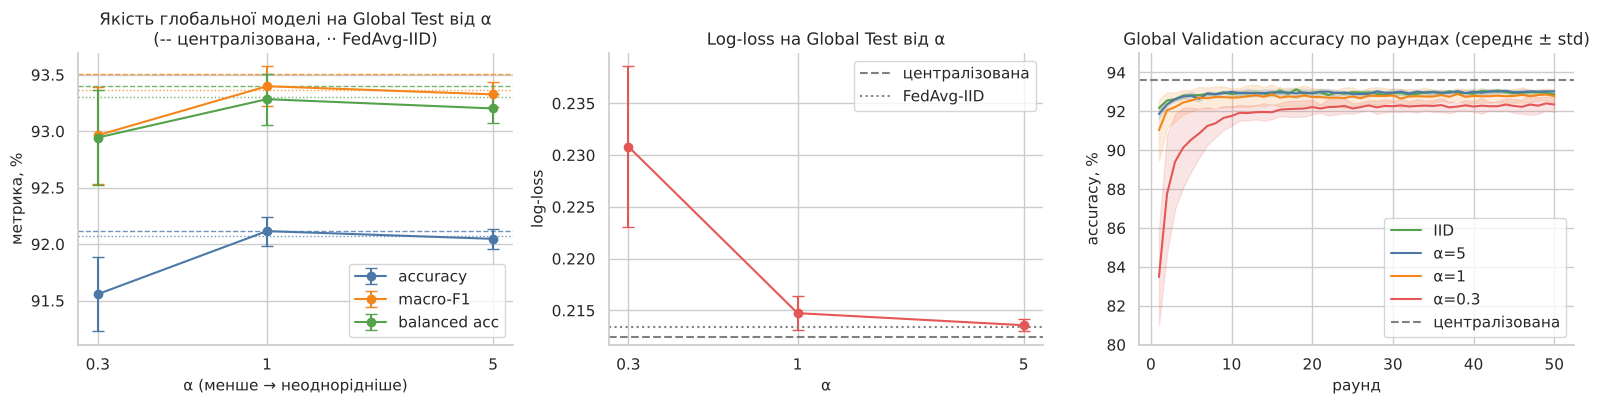

In [23]:
alphas = [0.3, 1, 5]
def collect(kind, metric):
    v = np.array([exp1[(kind, s)]["test"][metric] for s in SEEDS]); return v.mean(), v.std()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = {"accuracy": "#4C78A8", "macro_f1": "#F58518", "balanced_acc": "#54A24B"}
names = {"accuracy": "accuracy", "macro_f1": "macro-F1", "balanced_acc": "balanced acc"}
for m, col in cols.items():
    mu = np.array([collect(a_, m)[0] for a_ in alphas]); sd = np.array([collect(a_, m)[1] for a_ in alphas])
    axes[0].errorbar(alphas, mu * 100, yerr=sd * 100, fmt="o-", capsize=4, color=col, label=names[m])
    axes[0].axhline(central_test[m] * 100, color=col, ls="--", lw=1, alpha=0.8)
    axes[0].axhline(collect("iid", m)[0] * 100, color=col, ls=":", lw=1, alpha=0.8)
axes[0].set_xscale("log"); axes[0].set_xticks(alphas); axes[0].set_xticklabels([str(a_) for a_ in alphas]); axes[0].minorticks_off()
axes[0].set(title="Якість глобальної моделі на Global Test від α\n(-- централізована, ·· FedAvg-IID)", xlabel="α (менше → неоднорідніше)", ylabel="метрика, %")
axes[0].legend(loc="lower right")

mu = np.array([collect(a_, "log_loss")[0] for a_ in alphas]); sd = np.array([collect(a_, "log_loss")[1] for a_ in alphas])
axes[1].errorbar(alphas, mu, yerr=sd, fmt="o-", capsize=4, color="#E45756")
axes[1].axhline(central_test["log_loss"], color="gray", ls="--", label="централізована")
axes[1].axhline(collect("iid", "log_loss")[0], color="gray", ls=":", label="FedAvg-IID"); axes[1].legend()
axes[1].set_xscale("log"); axes[1].set_xticks(alphas); axes[1].set_xticklabels([str(a_) for a_ in alphas]); axes[1].minorticks_off()
axes[1].set(title="Log-loss на Global Test від α", xlabel="α", ylabel="log-loss")

pal = {"iid": "#54A24B", 5: "#4C78A8", 1: "#F58518", 0.3: "#E45756"}
for kind in EXP1_KINDS:
    curves = np.array([exp1[(kind, s)]["hist"]["val_acc"] for s in SEEDS]) * 100
    x = np.arange(1, ROUNDS + 1)
    axes[2].plot(x, curves.mean(0), color=pal[kind], label="IID" if kind == "iid" else f"α={kind}")
    axes[2].fill_between(x, curves.mean(0) - curves.std(0), curves.mean(0) + curves.std(0), color=pal[kind], alpha=0.15)
axes[2].axhline(central_val["accuracy"] * 100, color="gray", ls="--", label="централізована")
axes[2].set(title="Global Validation accuracy по раундах (середнє ± std)", xlabel="раунд", ylabel="accuracy, %", ylim=(80, 95)); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

### Висновки Експерименту 1 (вплив неоднорідності, E = 5, 5 розбиттів)

| розподіл | label-skew | drift | accuracy | macro-F1 | log-loss |
|---|---|---|---|---|---|
| IID | 0.001 | 0.49 | 0.9208 ± 0.0008 | 0.9337 | 0.2134 ± 0.0002 |
| α = 5 | 0.14 | 0.64 | 0.9205 ± 0.0010 | 0.9333 | 0.2136 ± 0.0007 |
| α = 1 | 0.28 | 0.90 | 0.9212 ± 0.0014 | 0.9340 | 0.2147 ± 0.0018 |
| **α = 0.3** | **0.45** | **1.43** | **0.9156 ± 0.0037** | **0.9296** | **0.2308 ± 0.0087** |
| централізована | — | — | 0.9212 | 0.9350 | 0.2124 |

**Що показано і яка закономірність.** Для IID, α = 5 та α = 1 глобальна модель **практично збігається з централізованою** (accuracy 0.9205–0.9212 проти 0.9212; log-loss на 0.5–1 % вище). Помітне погіршення з'являється лише при сильній неоднорідності **α = 0.3**: accuracy −0.56 п.п., macro-F1 −0.54 п.п., balanced accuracy −0.46 п.п., log-loss **+8.7 %**; крім того, **розкид між розбиттями зростає у ≈ 3–5 разів** (std accuracy 0.0037 проти ≤ 0.0014; std log-loss 0.0087 проти ≤ 0.0018) — результат починає залежати від того, який клієнт отримав який клас. Показник дрейфу зростає монотонно з неоднорідністю (0.49 → 0.64 → 0.90 → 1.43), що узгоджується з поясненням нижче. На кривих збіжності (права панель) α = 0.3 стартує помітно нижче (≈ 83.5 % на валідації після 1-го раунду проти ≈ 91–92 % у решти), має широку смугу невизначеності, виходить на плато за ≈ 15–20 раундів і лишається ≈ 0.7 п.п. нижче за інші криві.

**Чому Non-IID погіршує FedAvg.**
1. *Різні локальні оптимуми.* Клієнт мінімізує $F_k$, чий мінімум $w_k^\*$ не збігається з мінімумом глобальної цілі $F=\sum_k\frac{n_k}{n}F_k$. Кожна локальна епоха тягне модель до $w_k^\*$, а усереднені «тяги» вже не вказують на $w^\*$ (при $E>1$ нерухома точка FedAvg зсунута відносно $w^\*$, і зсув зростає з неоднорідністю та $E$). У IID всі $F_k$ майже однакові, тому $w_k^\*\approx w^\*$.
2. *Зміщення логітів відсутніх класів.* Клієнт без класу $c$ знижує логіти й зсув $b_c$ цього класу; після усереднення клас $c$ недооцінюється, що псує калібрування — звідси незрівнянно більше погіршення за log-loss (+8.7 %), ніж за accuracy.
3. *Збільшена дисперсія оновлень:* різні клієнти штовхають модель у різні боки, прогрес на раунд нестабільний.

**Чому ефект тут помірний.** Модель — *опукла лінійна* (єдиний басейн, 119 параметрів), усі 5 клієнтів беруть участь у кожному раунді, а локальних кроків небагато; за таких умов FedAvg «прощає» неоднорідність. Для нейромереж, часткової участі клієнтів чи більших $E$ деградація зазвичай значно сильніша — наш результат не слід екстраполювати.

**Чи може глобальна модель бути гіршою за централізовану?** Так, і тут це видно при α = 0.3 (−0.56 п.п. accuracy, +0.018 log-loss). Централізоване навчання оптимізує ту саму ціль $F$ з прямим доступом до всіх даних, а FedAvg — наближення, що ще й зміщується неоднорідністю; на практиці централізована модель — верхня межа, а глобальна FL-модель — її наближення (для IID і помірних α різниця статистично невловима; нерідкі «виграші» FL на соті відсотка — це шум).

**Чи може глобальна модель бути гіршою за деякі локальні?** На Global Test при Non-IID — ні: найкраща з локальних при α = 0.3 має 88.1 % проти 91.6 % у глобальної. Але *номінально* можливо: в IID найкраща з 5 локальних має 0.9213 проти 0.9208 у глобальної — це максимум із п'яти випадкових величин, у межах шуму (середня локальна — 0.9186). Істотно інакше на **локальному розподілі клієнта** — див. Етап 7: при α = 0.3 локальна модель на власних тестах має 95.3 % проти 91.7 % у глобальної, бо глобальна оптимізована «в середньому по всіх», а локальна використовує апріорний розподіл класів свого клієнта.

## 6.2 Порівняльна таблиця: локальні моделі, глобальна модель, централізована модель

Спершу детально для **α = 0.3, seed 0** (кожен клієнт окремо), потім зведено по всіх α (середнє по 5 seeds). Усі метрики — на **Global Test**.

In [24]:
r0 = exp1[(0.3, 0)]
parts0 = r0["parts"]
rows = []
for k, (p, met) in enumerate(zip(parts0, r0["local"])):
    present = int((np.bincount(y_pool[p], minlength=C) > 0).sum())
    rows.append({"модель": f"Локальна, клієнт {k + 1}", "n_k": len(p), "класів у даних": present, **met})
loc_df = pd.DataFrame(rows)
rows.append({"модель": "Локальні: середнє", "n_k": np.nan, "класів у даних": np.nan, **loc_df[METRICS].mean().to_dict()})
rows.append({"модель": "Локальні: найкраща", "n_k": np.nan, "класів у даних": np.nan, **loc_df[METRICS].max().to_dict() | {"log_loss": loc_df["log_loss"].min()}})
rows.append({"модель": "Глобальна FedAvg (α=0.3, E=5)", "n_k": len(y_pool), "класів у даних": C, **r0["test"]})
rows.append({"модель": "Централізована", "n_k": len(y_pool), "класів у даних": C, **central_test})
table_detail = pd.DataFrame(rows).set_index("модель")
display(table_detail.round(4))

,n_k,класів у даних,accuracy,macro_f1,balanced_acc,log_loss
модель,,,,,,
"Локальна, клієнт 1",3221.0,6.0,0.8511,0.7354,0.7496,1.3862
"Локальна, клієнт 2",2250.0,6.0,0.7169,0.7100,0.7561,1.3895
"Локальна, клієнт 3",3438.0,6.0,0.7542,0.6389,0.6610,1.8591
"Локальна, клієнт 4",1122.0,7.0,0.7018,0.7560,0.8167,1.1109
"Локальна, клієнт 5",176.0,7.0,0.8124,0.8087,0.8241,0.6884
Локальні: середнє,NaN,NaN,0.7673,0.7298,0.7615,1.2868
Локальні: найкраща,NaN,NaN,0.8511,0.8087,0.8241,0.6884
"Глобальна FedAvg (α=0.3, E=5)",10207.0,7.0,0.9182,0.9337,0.9321,0.2248
Централізована,10207.0,7.0,0.9212,0.9350,0.9340,0.2124


accuracy         macro_f1     balanced_acc         log_loss
розподіл модель                                                                                            
IID      Локальні (середнє по клієнтах)  0.9186 ± 0.0006  0.9316 ± 0.0006  0.9309 ± 0.0006  0.2216 ± 0.0008
         Локальна (найкраща)                      0.9213           0.9345           0.9343           0.2169
         Глобальна FedAvg                0.9208 ± 0.0008  0.9337 ± 0.0009  0.9330 ± 0.0013  0.2134 ± 0.0002
α = 5    Локальні (середнє по клієнтах)  0.9138 ± 0.0022  0.9274 ± 0.0017  0.9268 ± 0.0012  0.2361 ± 0.0095
         Локальна (найкраща)                      0.9196           0.9330           0.9329           0.2222
         Глобальна FedAvg                0.9205 ± 0.0010  0.9333 ± 0.0012  0.9320 ± 0.0014  0.2136 ± 0.0007
α = 1    Локальні (середнє по клієнтах)  0.8880 ± 0.0174  0.8947 ± 0.0256  0.8977 ± 0.0222  0.3626 ± 0.1503
         Локальна (найкраща)                      0.9132           0.9272           0.9285           0.2398
         Глобальна FedAvg                0.9212 ± 0.0014  0.9340 ± 0.0020  0.9328 ± 0.0025  0.2147 ± 0.0018
α = 0.3  Локальні (середнє по клієнтах)  0.7290 ± 0.0468  0.7069 ± 0.0443  0.7460 ± 0.0294  1.3436 ± 0.3274
         Локальна (найкраща)                      0.8813           0.8809           0.8836           0.3836
         Глобальна FedAvg                0.9156 ± 0.0037  0.9296 ± 0.0048  0.9294 ± 0.0047  0.2308 ± 0.0087
—        Централізована                           0.9212           0.9350           0.9340           0.2124

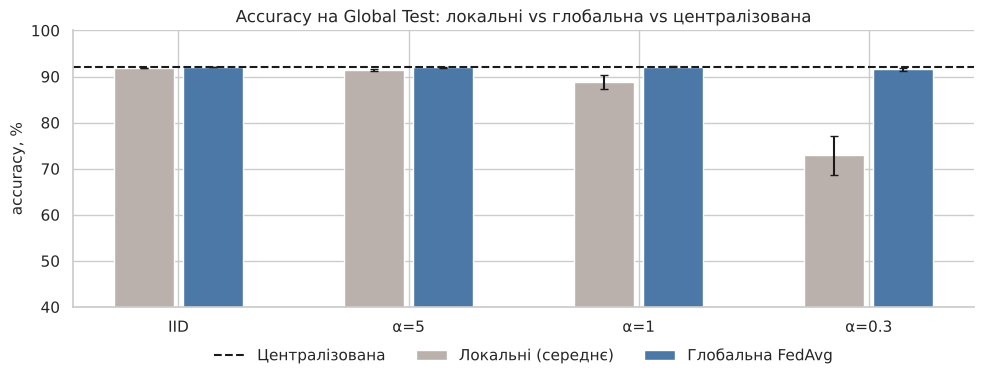

In [25]:
rows = []
for kind in EXP1_KINDS:
    rs = [exp1[(kind, s)] for s in SEEDS]
    label = "IID" if kind == "iid" else f"α = {kind}"
    loc_mean = pd.DataFrame([pd.DataFrame(r["local"])[METRICS].mean() for r in rs]).agg(["mean", "std"])
    loc_best = pd.DataFrame([pd.DataFrame(r["local"])[METRICS].agg({"accuracy": "max", "macro_f1": "max", "balanced_acc": "max", "log_loss": "min"}) for r in rs]).mean()
    glob = pd.DataFrame([r["test"] for r in rs])
    for name, vals in [("Локальні (середнє по клієнтах)", {m: f"{loc_mean.loc['mean', m]:.4f} ± {loc_mean.loc['std', m]:.4f}" for m in METRICS}),
                       ("Локальна (найкраща)", {m: f"{loc_best[m]:.4f}" for m in METRICS}),
                       ("Глобальна FedAvg", {m: fmt_ms(glob[m]) for m in METRICS})]:
        rows.append({"розподіл": label, "модель": name, **vals})
rows.append({"розподіл": "—", "модель": "Централізована", **{m: f"{central_test[m]:.4f}" for m in METRICS}})
summary = pd.DataFrame(rows).set_index(["розподіл", "модель"])
display(summary)

# візуально: accuracy на Global Test
fig, ax = plt.subplots(figsize=(10, 4))
labels = ["IID", "α=5", "α=1", "α=0.3"]
w = 0.26
for i, (name, fn, col) in enumerate([
        ("Локальні (середнє)", lambda rs: [pd.DataFrame(r["local"])["accuracy"].mean() for r in rs], "#BAB0AC"),
        ("Глобальна FedAvg", lambda rs: [r["test"]["accuracy"] for r in rs], "#4C78A8")]):
    mu = [np.mean(fn([exp1[(k, s)] for s in SEEDS])) * 100 for k in EXP1_KINDS]
    sd = [np.std(fn([exp1[(k, s)] for s in SEEDS])) * 100 for k in EXP1_KINDS]
    ax.bar(np.arange(4) + (i - 0.5) * w * 1.15, mu, w, yerr=sd, capsize=3, color=col, label=name)
ax.axhline(central_test["accuracy"] * 100, color="k", ls="--", label="Централізована")
ax.set_xticks(np.arange(4)); ax.set_xticklabels(labels); ax.set_ylim(40, 100)
ax.set(title="Accuracy на Global Test: локальні vs глобальна vs централізована", ylabel="accuracy, %")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

### Висновки порівняльних таблиць

* **Локальні моделі гірші й дуже нерівні.** При α = 0.3 (seed 0) accuracy локальних моделей на Global Test — від 70.2 % до 85.1 % (середня 76.7 %), macro-F1 — від 0.64 до 0.81, log-loss — 0.69–1.86 (у централізованої — 0.21). Причина: модель клієнта бачила лише частину класів/у спотворених пропорціях і не вміє розпізнавати те, чого не бачила. Показово, що якість визначається **складом даних, а не кількістю**: клієнт 5 із 176 прикладами має 81.2 %, клієнт 4 із 1 122 — 70.2 %.
* **Глобальна FedAvg-модель** (91.8 % accuracy, macro-F1 0.934, log-loss 0.225) дає майже якість централізованої (92.1 %, 0.935, 0.212), хоча жоден клієнт не передав жодного сирого прикладу — це і є мета FL.
* **Користь від федерації росте з неоднорідністю.** Середня локальна модель проти глобальної (accuracy на Global Test): IID — 0.9186 vs 0.9208 (+0.2 п.п.), α = 5 — 0.9138 vs 0.9205, α = 1 — 0.8880 vs 0.9212, **α = 0.3 — 0.7290 vs 0.9156 (+18.7 п.п.)**. У IID виграш мізерний: 2 000 прикладів уже достатньо для 119 параметрів, тож «обмін знаннями» нічого не додає; у Non-IID кожен клієнт має лише спотворений зріз реальності, і колективне навчання критично.
* **Підсумок рейтингу:** централізована ≳ глобальна FedAvg ≫ локальні (при IID різниця між трьома зникає; при α = 0.3 локальні втрачають ≈ 19 п.п., глобальна — ≈ 0.6 п.п.).

## Експеримент 2. Вплив кількості локальних епох E (α = 0.3; E = 1, 5, 10)

Кількість раундів однакова (`ROUNDS`), тому більше E = більше локальних обчислень на раунд. Окремо показано вигляд «за сумарною кількістю локальних епох» (раунди × E), щоб порівняти ефективність зв'язку й обчислень.

Експеримент 2 за 44 с


,accuracy,macro_f1,balanced_acc,log_loss,drift (сер. останніх 10 раундів),раундів до val acc ≥ 90%
E,,,,,,
1,0.9183 ± 0.0036,0.9319 ± 0.0038,0.9305 ± 0.0038,0.2283 ± 0.0074,0.8298,5.6 (5/5 seeds)
5,0.9156 ± 0.0037,0.9296 ± 0.0048,0.9294 ± 0.0047,0.2308 ± 0.0087,1.4284,4.6 (5/5 seeds)
10,0.9124 ± 0.0045,0.9264 ± 0.0059,0.9263 ± 0.0045,0.2363 ± 0.0097,1.7353,3.8 (5/5 seeds)


Парна різниця (E=1) − (E=10): accuracy +0.59 п.п. (±0.35), E=1 краще у 5/5 seeds; log-loss(E=10) − log-loss(E=1) = +0.0080 (±0.0033), E=1 краще у 5/5 seeds


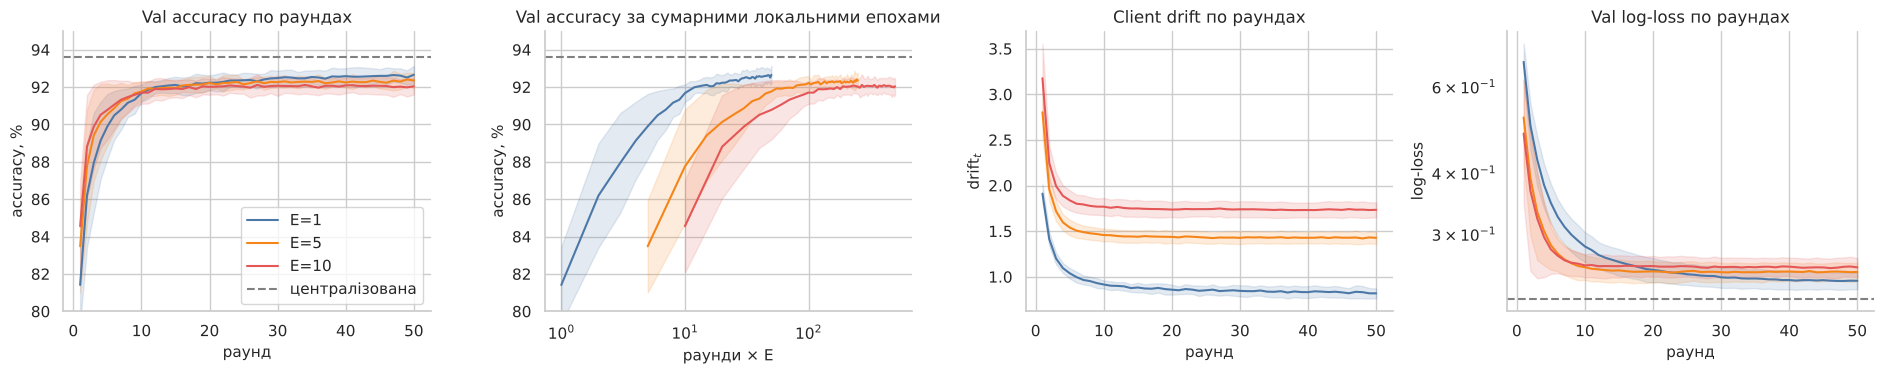

In [26]:
E_LIST = [1, 5, 10]
t0 = time.time()
exp2 = {}
for E in E_LIST:
    for s in SEEDS:
        exp2[(E, s)] = exp1[(0.3, s)] if E == E_DEFAULT else run_scenario(0.3, E, s)    # E=5, α=0.3 вже пораховано в Експ. 1
print(f"Експеримент 2 за {time.time() - t0:.0f} с")

TAU = 0.90   # поріг val accuracy для метрики «раундів до досягнення»
def rounds_to(curve, tau):
    hit = np.where(np.array(curve) >= tau)[0]
    return hit[0] + 1 if len(hit) else np.nan

rows = []
for E in E_LIST:
    rs = [exp2[(E, s)] for s in SEEDS]
    row = {"E": E}
    for m in METRICS:
        row[m] = fmt_ms(pd.Series([r["test"][m] for r in rs]))
    row["drift (сер. останніх 10 раундів)"] = np.mean([np.mean(r["hist"]["drift"][-10:]) for r in rs])
    rt = [rounds_to(r["hist"]["val_acc"], TAU) for r in rs]
    row[f"раундів до val acc ≥ {TAU:.0%}"] = f"{np.nanmean(rt):.1f} ({int(np.sum(~np.isnan(rt)))}/{len(rt)} seeds)" if not np.all(np.isnan(rt)) else f"не досягнуто (0/{len(rt)})"
    rows.append(row)
exp2_table = pd.DataFrame(rows).set_index("E")
display(exp2_table)

# парне порівняння за seed-ами (той самий розподіл даних для різних E): E=1 проти E=10
d_acc = np.array([exp2[(1, s)]["test"]["accuracy"] - exp2[(10, s)]["test"]["accuracy"] for s in SEEDS])
d_ll = np.array([exp2[(10, s)]["test"]["log_loss"] - exp2[(1, s)]["test"]["log_loss"] for s in SEEDS])
print(f"Парна різниця (E=1) − (E=10): accuracy {d_acc.mean() * 100:+.2f} п.п. (±{d_acc.std() * 100:.2f}), E=1 краще у {int((d_acc > 0).sum())}/{len(SEEDS)} seeds; "
      f"log-loss(E=10) − log-loss(E=1) = {d_ll.mean():+.4f} (±{d_ll.std():.4f}), E=1 краще у {int((d_ll > 0).sum())}/{len(SEEDS)} seeds")

fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))
pal = {1: "#4C78A8", 5: "#F58518", 10: "#E45756"}
x = np.arange(1, ROUNDS + 1)
for E in E_LIST:
    rs = [exp2[(E, s)]["hist"] for s in SEEDS]
    acc = np.array([h["val_acc"] for h in rs]) * 100; dr = np.array([h["drift"] for h in rs]); ls = np.array([h["val_loss"] for h in rs])
    for ax, data, xs in [(axes[0], acc, x), (axes[2], dr, x), (axes[3], ls, x), (axes[1], acc, x * E)]:
        ax.plot(xs, data.mean(0), color=pal[E], label=f"E={E}")
        ax.fill_between(xs, data.mean(0) - data.std(0), data.mean(0) + data.std(0), color=pal[E], alpha=0.15)
axes[0].axhline(central_val["accuracy"] * 100, color="gray", ls="--", label="централізована")
axes[0].set(title="Val accuracy по раундах", xlabel="раунд", ylabel="accuracy, %", ylim=(80, 95))
axes[1].axhline(central_val["accuracy"] * 100, color="gray", ls="--")
axes[1].set(title="Val accuracy за сумарними локальними епохами", xlabel="раунди × E", ylabel="accuracy, %", xscale="log", ylim=(80, 95))
axes[2].set(title="Client drift по раундах", xlabel="раунд", ylabel=r"drift$_t$")
axes[3].axhline(central_val["log_loss"], color="gray", ls="--")
axes[3].set(title="Val log-loss по раундах", xlabel="раунд", ylabel="log-loss", yscale="log")
axes[0].legend(loc="lower right"); plt.tight_layout(); plt.show()

### Висновки Експерименту 2 (α = 0.3; E = 1, 5, 10)

| E | accuracy | macro-F1 | log-loss | drift | раундів до val acc ≥ 90 % |
|---|---|---|---|---|---|
| 1 | 0.9183 ± 0.0036 | 0.9319 | 0.2283 ± 0.0074 | 0.83 | 5.6 |
| 5 | 0.9156 ± 0.0037 | 0.9296 | 0.2308 ± 0.0087 | 1.43 | 4.6 |
| 10 | 0.9124 ± 0.0045 | 0.9264 | 0.2363 ± 0.0097 | 1.74 | 3.8 |

**Що показано.** Зі зростанням $E$ **фінальна якість монотонно погіршується**, а **дрейф зростає більш ніж удвічі** (0.83 → 1.74). Окремі різниці (≈ 0.3 п.п. між сусідніми $E$) порівнянні зі std, але парне порівняння на тих самих розбиттях це підтверджує: E = 1 краще за E = 10 **у 5 з 5 seed-ів** (в середньому на +0.59 п.п. accuracy і −0.008 log-loss). Водночас більше $E$ **прискорює збіжність за кількістю раундів**: 90 % val accuracy досягається за ≈ 3.8 раунду при E = 10 проти ≈ 5.6 при E = 1. Тобто це компроміс **«вартість зв'язку ↔ якість»**: більше локальної роботи — менше раундів комунікації, але гірша межа. У перерахунку на сумарні локальні епохи (друга панель) E = 1 найефективніший за обчисленнями — додаткові локальні епохи після певного моменту лише «женуть» клієнта до його власного оптимуму.

**Що таке client drift.** Клієнтський дрейф — це надмірне відхилення локальних моделей від глобальної (і одна від одної) під час локального навчання. Кожен клієнт робить $E$ епох SGD на **власній** цілі $F_k$ і віддаляється від $w^t$ у напрямку власного мінімуму $w_k^\*$; якщо дані Non-IID, ці напрямки суттєво різні. Ми вимірюємо його як зважений розкид $\sum_k p_k\lVert w_k^{t+1}-w^{t+1}\rVert_F$.

**Чому велике E шкодить у Non-IID.** Чим довше клієнт навчається локально, тим далі він іде від $w^t$ до $w_k^\*$ (розкид клієнтів росте з E, хоч і сублінійно: 0.83 → 1.43 → 1.74 — див. панель дрейфу), і середнє дуже різних моделей — це вже не крок у напрямку глобального мінімуму, а точка зі зсувом (нерухома точка FedAvg відхиляється від $w^\*$ тим більше, чим більші $E\cdot\text{lr}$ і неоднорідність). При $E=1$ і повному батчі FedAvg еквівалентний централізованому градієнтному кроку; при великому $E$ — ні. У IID-даних усі $w_k^\*$ майже збігаються, тому велике $E$ там майже безкоштовне. **Практика:** брати помірне $E$ (1–5), зменшувати lr із раундами або додавати корекцію дрейфу (FedProx, SCAFFOLD) — особливо для нелінійних моделей, де цей ефект значно виразніший, ніж у нашій опуклій регресії.

---
# Етап 7. Додатковий експеримент Б — персоналізація

**Ідея.** Після отримання глобальної моделі кожен клієнт **донавчає її локально 1–2 епохи** на своїх даних. Порівнюємо на **локальних тестових вибірках клієнтів**: глобальну модель, персоналізовані моделі та локальні моделі «з нуля».

**Методика (без порушення принципів доступу):**
* кожна клієнтська вибірка $D_k$ ділиться 80/20 на локальну train та локальну test (відтворювано, на стороні клієнта); FedAvg навчається лише на локальних train-частинах;
* локальна test-вибірка клієнта має **його власний** розподіл класів, тому вона відображає реальне використання моделі на цьому клієнті;
* додатково вимірюємо, **якої ціни** коштує персоналізація: якість персоналізованих моделей на Global Test.

Метрики на локальних тестах усереднюються з вагою розміру локального тесту (= метрика на об'єднаних локальних тестах); для кожного α — 5 розбиттів.

In [27]:
def split_local(parts, seed, test_frac=0.2):
    """Кожен клієнт ділить свої дані 80/20 на локальні train / test (на стороні клієнта)."""
    rng = np.random.default_rng(seed + 1000)
    tr, te = [], []
    for p in parts:
        q = rng.permutation(p)
        n_te = max(2, int(round(test_frac * len(q))))
        te.append(np.sort(q[:n_te])); tr.append(np.sort(q[n_te:]))
    return tr, te


def eval_on(model, idx):
    """Метрики на довільній підмножині FL Train Pool (локальний тест клієнта)."""
    X, y = X_pool[idx], y_pool[idx]
    P = model.predict_proba(X)
    pred = P.argmax(1)
    return {"acc": float(np.mean(pred == y)), "log_loss": float(log_loss(y, P, labels=np.arange(C)))}


PERS_EPOCHS = [1, 2]
rows = []
t0 = time.time()
for alpha in [5, 1, 0.3]:
    for s in SEEDS:
        parts = make_partition(alpha, y_pool, K_CLIENTS, s)
        tr_idx, te_idx = split_local(parts, s)
        clients = make_clients(tr_idx)
        server, _ = run_fedavg(clients, ROUNDS, E_DEFAULT, HP["lr"], HP["batch_size"], HP["lam"], X_val, Y_val, seed=s)
        local_only = train_local_models(clients, ROUNDS * E_DEFAULT, HP, seed=s)
        for k, c in enumerate(clients):
            variants = {"Глобальна (FedAvg)": server}
            for pe in PERS_EPOCHS:                                           # персоналізація: донавчання від w^T
                pm = MulticlassLogisticRegression(D, C, HP["lam"]); pm.set_params(*server.get_params())
                pm.fit(c.X, c.Y, lr=HP["lr"], batch_size=HP["batch_size"], epochs=pe, seed=s * 100 + k, track=False)
                variants[f"Персоналізована (+{pe} ep)"] = pm
            variants["Локальна «з нуля»"] = local_only[k]
            for name, mdl in variants.items():
                loc = eval_on(mdl, te_idx[k])
                rows.append({"α": alpha, "seed": s, "client": k, "модель": name, "n_test": len(te_idx[k]),
                             **loc, "global_test_acc": float(np.mean(mdl.predict(X_test) == y_test))})
pers = pd.DataFrame(rows)
print(f"Експеримент Б: {time.time() - t0:.0f} с, {len(pers)} записів")

pw = pers.assign(**{c + "_w": pers[c] * pers["n_test"] for c in ["acc", "log_loss"]})
grp = pw.groupby(["α", "модель", "seed"])
per_seed = pd.DataFrame({"local_acc": grp["acc_w"].sum() / grp["n_test"].sum(),
                         "local_loss": grp["log_loss_w"].sum() / grp["n_test"].sum(),
                         "global_acc": grp["global_test_acc"].mean()}).reset_index()
order = ["Глобальна (FedAvg)", "Персоналізована (+1 ep)", "Персоналізована (+2 ep)", "Локальна «з нуля»"]
tbl = per_seed.groupby(["α", "модель"]).agg(["mean", "std"]).drop(columns="seed")
tbl.columns = [f"{a}_{b}" for a, b in tbl.columns]
tbl = tbl.reindex(pd.MultiIndex.from_product([[5, 1, 0.3], order], names=["α", "модель"]))
disp = pd.DataFrame({
    "локальний тест: accuracy": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tbl["local_acc_mean"], tbl["local_acc_std"])],
    "локальний тест: log-loss": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tbl["local_loss_mean"], tbl["local_loss_std"])],
    "Global Test: accuracy": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tbl["global_acc_mean"], tbl["global_acc_std"])]}, index=tbl.index)
display(disp)

Експеримент Б: 99 с, 300 записів


локальний тест: accuracy локальний тест: log-loss Global Test: accuracy
α   модель                                                                                         
5.0 Глобальна (FedAvg)               0.9196 ± 0.0049          0.2255 ± 0.0098       0.9209 ± 0.0013
    Персоналізована (+1 ep)          0.9208 ± 0.0068          0.2178 ± 0.0115       0.9189 ± 0.0009
    Персоналізована (+2 ep)          0.9216 ± 0.0062          0.2175 ± 0.0118       0.9178 ± 0.0018
    Локальна «з нуля»                0.9191 ± 0.0064          0.2278 ± 0.0164       0.9137 ± 0.0021
1.0 Глобальна (FedAvg)               0.9226 ± 0.0052          0.2245 ± 0.0192       0.9197 ± 0.0027
    Персоналізована (+1 ep)          0.9330 ± 0.0024          0.2006 ± 0.0164       0.9137 ± 0.0033
    Персоналізована (+2 ep)          0.9348 ± 0.0030          0.1980 ± 0.0166       0.9087 ± 0.0063
    Локальна «з нуля»                0.9328 ± 0.0039          0.1979 ± 0.0213       0.8878 ± 0.0178
0.3 Глобальна (FedAvg)               0.9172 ± 0.0061          0.2440 ± 0.0148       0.9152 ± 0.0034
    Персоналізована (+1 ep)          0.9490 ± 0.0084          0.1674 ± 0.0235       0.8968 ± 0.0073
    Персоналізована (+2 ep)          0.9515 ± 0.0072          0.1607 ± 0.0230       0.8814 ± 0.0108
    Локальна «з нуля»                0.9531 ± 0.0069          0.1544 ± 0.0271       0.7186 ± 0.0534

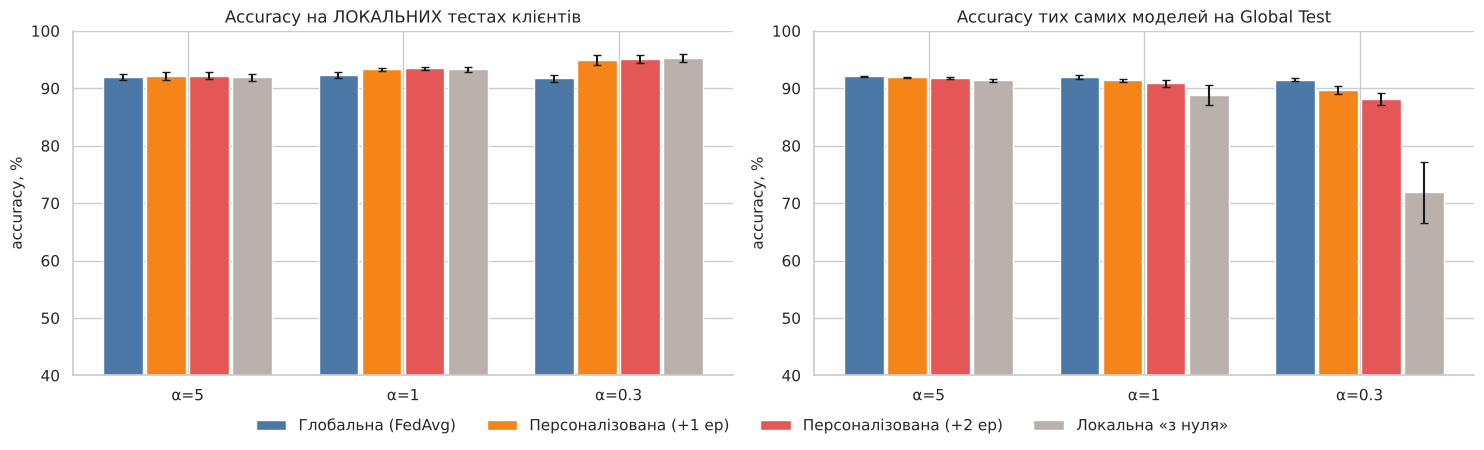

Accuracy на локальному тесті кожного клієнта (α = 0.3, seed 0):


модель,n_test,Глобальна (FedAvg),Персоналізована (+1 ep),Персоналізована (+2 ep),Локальна «з нуля»
клієнт 1,644,0.9255,0.9472,0.9550,0.9581
клієнт 2,450,0.9444,0.9600,0.9578,0.9622
клієнт 3,688,0.8983,0.9113,0.9186,0.9215
клієнт 4,224,0.9152,0.9598,0.9643,0.9598
клієнт 5,35,0.8857,0.8857,0.9143,0.9143


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
pal_m = dict(zip(order, ["#4C78A8", "#F58518", "#E45756", "#BAB0AC"]))
w = 0.2
for ax, col, title in [(axes[0], "local_acc", "Accuracy на ЛОКАЛЬНИХ тестах клієнтів"), (axes[1], "global_acc", "Accuracy тих самих моделей на Global Test")]:
    for i, name in enumerate(order):
        mu = [per_seed[(per_seed["α"] == a_) & (per_seed["модель"] == name)][col].mean() * 100 for a_ in [5, 1, 0.3]]
        sd = [per_seed[(per_seed["α"] == a_) & (per_seed["модель"] == name)][col].std() * 100 for a_ in [5, 1, 0.3]]
        ax.bar(np.arange(3) + (i - 1.5) * w, mu, w * 0.92, yerr=sd, capsize=3, color=pal_m[name], label=name)
    ax.set_xticks(np.arange(3)); ax.set_xticklabels(["α=5", "α=1", "α=0.3"]); ax.set_ylim(40, 100)
    ax.set(title=title, ylabel="accuracy, %")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()

# по-клієнтна картина для α=0.3, seed 0
g = pers[(pers["α"] == 0.3) & (pers["seed"] == 0)].pivot(index="client", columns="модель", values="acc")[order]
g.insert(0, "n_test", pers[(pers["α"] == 0.3) & (pers["seed"] == 0) & (pers["модель"] == order[0])].set_index("client")["n_test"])
g.index = [f"клієнт {k + 1}" for k in g.index]
print("Accuracy на локальному тесті кожного клієнта (α = 0.3, seed 0):")
display(g.round(4))

### Висновки Експерименту Б (персоналізація)

| α | модель | accuracy на локальних тестах | log-loss (локальні) | accuracy на Global Test |
|---|---|---|---|---|
| 0.3 | глобальна | 0.9172 | 0.2440 | 0.9152 |
| 0.3 | +1 епоха | 0.9490 | 0.1674 | 0.8968 |
| 0.3 | +2 епохи | 0.9515 | 0.1607 | 0.8814 |
| 0.3 | локальна «з нуля» | 0.9531 | 0.1544 | 0.7186 |

* **Персоналізація допомагає тим більше, чим неоднорідніші дані.** Донавчання на 1 епоху піднімає локальну accuracy на **+0.1 п.п. при α = 5** (в межах шуму), **+1.0 п.п. при α = 1** і **+3.2 п.п. при α = 0.3** (log-loss 0.244 → 0.167); друга епоха додає ще ≈ +0.25 п.п. при α = 0.3. Причина: локальна тестова вибірка має *власний* розподіл класів клієнта (фактично інші апріорні ймовірності), а донавчання підлаштовує зсуви й ваги під нього; глобальна модель оптимізована під усереднений розподіл. В IID-подібних даних локальний розподіл ≈ глобальному — виграшу немає.
* **Ціна персоналізації — втрата загальності.** Ті самі моделі на Global Test: глобальна 91.5 %, +1 епоха — 89.7 %, +2 епохи — 88.1 %, повністю локальна — лише 71.9 %. Тобто **персоналізована модель — компроміс між глобальною та локальною**: бере майже весь локальний виграш (+3.2 з +3.6 п.п. у локальної «з нуля») і зберігає значно більше «світових» знань (89.7 % проти 71.9 %). Кожна додаткова епоха зсуває баланс у бік локальності.
* **Глобальна модель може бути гіршою за локальну на локальному розподілі** (91.7 % проти 95.3 % при α = 0.3) — це відповідь на питання про порівняння з локальними моделями: так, глобальна модель гірша на локальних даних клієнта, але локальна модель катастрофічно гірша поза ними.
* **Обмеження.** Клієнт 5 у по-клієнтній таблиці має лише 35 локальних тестових прикладів (1 приклад ≈ 2.9 п.п.), тож його окремі цифри шумні; висновки спираються на зважені середні за 5 розбиттями. Також локальний тест береться з тих самих даних клієнта, тому припускається, що майбутні дані клієнта мають той самий розподіл класів; якщо він змінюється, персоналізація може нашкодити.

---
# Відповіді на теоретичні питання

**1. Чому для багатокласової класифікації використовують softmax?**
Потрібен вектор ймовірностей: невід'ємні числа, що сумуються до 1. Softmax $P_{ic}=e^{Z_{ic}}/\sum_j e^{Z_{ij}}$ узагальнює сигмоїду на $C>2$ класів, диференційовний, зберігає порядок логітів і є канонічною функцією зв'язку для категоріального розподілу; разом із крос-ентропією дає простий градієнт $P-Y$.

**2. Чому крос-ентропія — природна функція втрат для логістичної регресії?**
Мінімізація $-\frac1m\sum\log P_{i,y_i}$ ≡ максимізація правдоподібності категоріальної моделі (MLE). Разом із softmax втрата **опукла** за $(W,b)$ (єдиний мінімум), а градієнт $P-Y$ не «гасне» при насиченні, на відміну від MSE; крім того, це строго правильна скорингова функція — оцінює якість самих ймовірностей.

**3. Чим Ridge відрізняється від Lasso?**
Ridge штрафує $\lVert W\rVert_2^2$: стискає ваги плавно, не обнуляє їх, добре працює з мультиколінеарними ознаками, диференційовний (градієнт $\lambda W$). Lasso штрафує $\lVert W\rVert_1$: дає розріджені розв'язки (вбудований відбір ознак), але не диференційовний у 0 та нестабільно вибирає серед сильно корельованих ознак (у нас таких 15 пар).

**4. Чому параметр зсуву $b$ зазвичай не регуляризують?**
$b$ лише зсуває рішення (поріг/апріорні частоти класів) і не впливає на складність моделі; штраф на нього змушував би прогнози тягнутися до рівномірних частот і робив би модель залежною від зсуву ознак/цілі. Вага $W$, навпаки, визначає чутливість до ознак, тож саме її обмежують.

**5. Що таке Data Leakage?**
Потрапляння в процес навчання/підготовки інформації з даних, яких модель не має бачити (валідація, тест, майбутнє), через що метрики завищені, а реальна якість гірша. Приклади: `fit` скалера на всьому датасеті, відбір ознак за кореляціями з тестом, підбір гіперпараметрів за тестом, target encoding без розділення, дублікати між train і test. У нашому пайплайні: поділ → одразу після нього всі «навчувані» кроки лише на FL Train Pool.

**6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?**
Вибір «найкращого» за тестом робить тест частиною процедури навчання: найкращий результат серед багатьох спроб частково є везінням на цьому тесті (selection bias). Тоді тестова метрика — оптимістична оцінка, а не незалежна. Для підбору існує Global Validation; Global Test торкаємося лише для фінальної оцінки.

**7. Чому параметри масштабування потрібно навчати лише на тренувальних даних?**
Бо середнє та std з валідації/тесту — це інформація про дані, яких у момент навчання «не існує»: у реальності нові дані приходять по одному, і їхню статистику невідомо наперед (витік). У FL до цього додається принцип: клієнти не бачать глобальних вибірок, сервер — сирих даних; тому статистики збирають лише з тренувальних даних (спрощено — з усього пулу, або федеративно через зважені $\mu_k,\sigma_k^2$ — див. Етап 1.3).

**8. Що таке федеративне навчання і які його переваги?**
Це парадигма, у якій модель навчається на розподілених даних, які не залишають своїх власників: клієнти тренують локально й надсилають серверу лише параметри (оновлення), сервер агрегує їх у глобальну модель. Переваги: приватність і юридична відповідність (GDPR, комерційна таємниця), відсутність передачі великих масивів даних, використання даних, які неможливо централізувати, масштабованість по клієнтах. Недоліки: Non-IID, вартість комунікації, гетерогенність пристроїв, і сам по собі FL не гарантує приватності (потрібні secure aggregation / differential privacy).

**9. Чому сервер не повинен отримувати сирі дані клієнтів?**
Приватність і право (персональні/комерційні дані), безпека (центральне сховище — ціль атаки), вартість передавання, довіра між учасниками. Це також фундамент самої постановки FL: інакше задача зводиться до централізованого навчання (Етап 3).

**10. Чому агрегація FedAvg використовує зважування за кількістю прикладів?**
Глобальна ціль — емпіричний ризик на всіх даних: $F(w)=\sum_k\frac{n_k}{n}F_k(w)$, тож клієнт з більшою вибіркою має відповідно більший внесок (при одному кроці градієнта зважене усереднення точно відтворює централізований крок). Це також логічно статистично: оцінка з більшої вибірки надійніша. Емпірично на нашому датасеті виграш не виявився статистично значущим (див. 5.3), але теоретичне обґрунтування лишається.

**11. Що станеться, якщо агрегувати параметри без зважування?**
Модель мінімізуватиме $\frac1K\sum_kF_k$, а не ризик на всіх даних: клієнт з 176 прикладами впливатиме так само, як з 3 400 — дані малих клієнтів «перепредставлені», оцінка шумніша, а фінальна модель зміщується до їхніх розподілів. При рівних $n_k$ зважене й просте середнє збігаються (перевірено в коді). У наших експериментах різниця була в межах шуму.

**12. Що таке Non-IID дані?**
Дані клієнтів, що не є незалежними вибірками з одного спільного розподілу. Типи: зсув міток (різні частки класів — наш випадок, Діріхле), зсув ознак (різні умови збору), зсув кількості (різні $n_k$), зсув концепту (одні й ті самі ознаки → різні мітки).

**13. Чому федеративне навчання може погіршуватися на Non-IID даних?**
Бо локальні цілі $F_k$ мають різні мінімуми $w_k^\*$; локальне навчання веде моделі в різні боки (дрейф), усереднення таких моделей не дає шуканого глобального оптимуму, а клієнти без деяких класів зміщують відповідні логіти вниз. Результат: повільніша і нестабільніша збіжність, нижча якість, більший розкид між запусками (у нас: α = 0.3 → +8.7 % log-loss, std ×3–5).

**14. Що таке клієнтський дрейф (client drift)?**
Відхилення локальних моделей від глобальної (і одна від одної) за час $E$ локальних епох через те, що кожен клієнт оптимізує власну ціль. Вимірюється, наприклад, розкидом $\sum_kp_k\lVert w_k^{t+1}-w^{t+1}\rVert$: у нас він зростає з неоднорідністю (0.49 → 1.43 при IID → α = 0.3) та з $E$ (0.83 → 1.74 при E = 1 → 10).

**15. Як кількість локальних епох впливає на глобальну модель?**
Більше $E$ → менше раундів до заданої якості (3.8 проти 5.6 раундів до 90 %), але більший дрейф і гірша фінальна якість у Non-IID (accuracy 0.9183 → 0.9124, log-loss 0.2283 → 0.2363). У IID-даних вплив малий. Тобто $E$ регулює компроміс «комунікація ↔ якість».

**16. Чи може глобальна модель бути гіршою за централізовану? Чому?**
Так. Централізована оптимізує ту саму ціль з доступом до всіх даних; FedAvg — наближення, що при $E>1$ та Non-IID збігається до точки, зміщеної від справжнього мінімуму, і до того ж обмежене комунікацією. У нас при α = 0.3: 0.9156 проти 0.9212 (log-loss 0.2308 проти 0.2124), при IID/α ≥ 1 — різниця в межах шуму.

**17. Які метрики краще використовувати для багатокласової класифікації з можливим дисбалансом класів?**
Не лише accuracy (домінують великі класи): **macro-F1** (усереднює F1 по класах без урахування їхньої частоти), **balanced accuracy** (середній recall по класах), по-класові precision/recall і **матрицю плутанини**, а для якості ймовірностей — **log-loss**. У нас клас Bombay становить 3.8 %, а в Non-IID-клієнтах класи зникають зовсім — тому macro-F1/balanced accuracy розходяться з accuracy (наприклад, у локальних моделей при α = 0.3: accuracy 0.729, macro-F1 0.707, balanced accuracy 0.746).

---
# Загальний висновок

1. **Дані й методологія.** Dry Bean (13 611 зерен, 7 класів, 16 ознак, без пропусків) підходить для FL: достатньо прикладів для K=5 клієнтів і природна неоднорідність сортів. Поділ 15 / 10 / 75 % стратифіковано й виконано **першим**; скалер, відбір ознак та гіперпараметри визначалися без тесту, тож Data Leakage виключено.
2. **Модель.** Багатокласова логістична регресія з Ridge реалізована на NumPy повністю векторизовано, градієнти перевірено чисельно (похибка ≈ $10^{-8}$). Без регуляризації та з малою λ модель не перенавчається ($m\gg d$); вибрано λ = 10⁻⁴, lr = 0.1, batch = 16, усі 16 ознак.
3. **Централізована база:** accuracy 0.9212, macro-F1 0.9350, balanced accuracy 0.9340, log-loss 0.2124; основна плутанина — Sira ↔ Dermason, Bombay розпізнається ідеально.
4. **Неоднорідність — головний ворог FL.** При IID, α = 5 та α = 1 FedAvg практично не відрізняється від централізованого навчання; при α = 0.3 accuracy падає на ≈ 0.6 п.п., log-loss зростає на ≈ 9 %, а розкид між розбиттями збільшується у 3–5 разів (при α = 0.1 — ще сильніше, accuracy ≈ 89.5 %).
5. **Федерація виправдовує себе, коли локальних даних недостатньо «за складом».** Локальні моделі при α = 0.3 мають лише ≈ 73 % на Global Test проти 91.6 % у глобальної; в IID користі від FL майже немає (+0.2 п.п.).
6. **Локальні епохи.** Більше E → швидша збіжність за раундами, але більший client drift і нижча якість у Non-IID (E = 1 краще за E = 10 у 5/5 розбиттів).
7. **Персоналізація** (додатковий експеримент) дає +3 п.п. на локальних даних при α = 0.3 ціною падіння якості на глобальному розподілі (91.5 → 89.7 %), що значно краще, ніж повністю локальні моделі (71.9 %).

**Обмеження та застереження.** Один датасет, лінійна опукла модель, K = 5, усі клієнти беруть участь у кожному раунді, 5 розбиттів на конфігурацію; різниці порядку 0.1–0.3 п.п. лежать у межах шуму й не інтерпретуються як ефекти. У нейромережах, при частковій участі клієнтів або більшій кількості локальних кроків деградація від Non-IID буде значно сильнішою. FL сам по собі не гарантує приватності (параметри теж можуть «витікати» — потрібні secure aggregation та differential privacy).